# Predicting the final size of US wildfires — a clean, explicit pipeline

Group members: Hugo Ramillon, Sasha Sutton, *(add the other members here)*
Course: Hands-on Machine Learning — S1 DKAI

Data (not included in this repository):
[*1.88 Million US Wildfires* on Kaggle](https://www.kaggle.com/datasets/rtatman/188-million-us-wildfires) (R. Tatman), built from
Short, K. C. (2017). *Spatial wildfire occurrence data for the United States, 1992–2015 [FPA_FOD_20170508]*, 4th ed., USDA Forest Service Research Data Archive, <https://doi.org/10.2737/RDS-2013-0009.4>.
To run the notebook, unzip `archive.zip` and place `FPA_FOD_20170508.sqlite` at `../data/data.sqlite`.

### Contents
1. Introduction: task, framing, state of the art
2. Loading the data
3. Column audit: what we keep, what we drop, and why
4. Cleaning & feature engineering
5. Exploratory data analysis
6. Correlations & feature relevance
7. Train / validation / test protocol
8. Preprocessing pipelines
9. Model comparison
10. Hyperparameter tuning
11. PCA: does dimensionality reduction help?
12. Ablation study
13. Final evaluation on the test set
14. Why the evaluation protocol matters
15. Conclusion

## 1. Introduction

### 1.1 The task in our own words
Every wildfire reported in the US between 1992 and 2015 (1.88 M fires) is recorded with where it started, when it was discovered, who reported it, what caused it and, at the very end, how many acres it burned (`FIRE_SIZE`).

We want to predict the final burned area of a fire from information that is cheap and available early. A good estimate at discovery time would help to triage fires and allocate firefighting resources. The target is hard to get (it is only known after the fire is out and the perimeter has been mapped), while the inputs (date, time, coordinates, reporting agency, cause) are recorded when the fire is reported. That is the kind of problem the project guidelines recommend.

### 1.2 Framing
* Target: `LOG_SIZE = log(1 + FIRE_SIZE)`. Fire sizes go from 0.00001 to 600,000 acres, with a heavy right tail (Section 5.1). On the raw scale, a squared error would be driven entirely by a handful of mega-fires. On the log scale, the model has to get the order of magnitude right, which is what matters operationally.
* Two scenarios, kept separate on purpose:
  * Scenario A, "at discovery" (main): only features known when the fire is reported. This is the realistic, leakage-free setting.
  * Scenario B, "after containment": A + the duration of the fire (containment date − discovery date). Duration is only known once the fire is controlled, so it is *not* available for early prediction. It is very informative, though, so we keep it as an upper-bound reference and quantify how much of the performance comes from it. Mixing the two scenarios is the most common way to get an over-optimistic score on this dataset.
* Why regression and not classification of size classes? The official classes A–G are just bins of the size. Predicting the continuous (log) size keeps the order between classes (confusing A with G is much worse than A with B) and lets us derive classes, or a "large fire" alarm, afterwards.
* Metrics (on the log scale): R² (share of variance explained, 0 = predicting the mean), RMSE and MAE. We also convert predictions back to the official size classes A–G to report a classification accuracy, and we train a dedicated "large fire" (≥ 100 acres) detector (Section 13.5).

### 1.3 State of the art
The dataset is well studied, but mostly for cause prediction rather than size:

| Work | Task | Approach | Reported result |
|---|---|---|---|
| Kaggle notebooks / [JamesonThai/wildfire](https://github.com/JamesonThai/wildfire) | Cause (13 classes / 3 classes) | Random Forest, XGBoost | ≈ 59–60 % (13 cl.), ≈ 80–81 % (3 cl.) accuracy |
| UCLA thesis ([eScholarship](https://escholarship.org/uc/item/44j0g4pk)) | Fire size (1992–2015 FPA-FOD) | XGBoost, CatBoost, RF, GLM, MLP | Boosting best; XGBoost better on small fires, CatBoost on large ones; class imbalance is the main difficulty |
| [NHSJS paper](https://nhsjs.com/?p=23708) | Size class (5 classes) | Logistic regression, MLP | > 82 % accuracy (classes not comparable to ours, dominated by small fires) |
| Koh (2023), *Extremes* ([PMC](https://pmc.ncbi.nlm.nih.gov/articles/PMC10115709/)) | EVA 2021 challenge: monthly burned area per grid cell | Gradient boosting + extreme-value losses | 2nd / 28; spatio-temporal CV is a better proxy of test error than random K-fold |
| Pourmohamad et al. (2024), *ESSD* ([paper](https://essd.copernicus.org/articles/16/3045/2024/essd-16-3045-2024.html)) | FPA-FOD-Attributes: +270 covariates (weather, vegetation, social) | Dataset paper | Shows that richer environmental covariates are the natural next step |

Takeaways for our work: (1) gradient-boosted trees are the reference model on this data; (2) accuracies on size *classes* look high only because most fires are tiny (always predicting class B already gives ≈ 50 %), so we report regression metrics and a baseline every time; (3) evaluation protocol matters: random splits on spatio-temporal data are optimistic.

What is original here: we predict the continuous (log) burned area *at discovery*, with an explicit leakage audit, a temporal split (train on the past, test on the future), a systematic model comparison, PCA, hyperparameter search and an ablation over feature groups, and we measure how much the containment-time information (duration) adds.

## 2. Loading the data

Why this step? The raw file is an ≈ 800 MB SQLite database with 39 columns and 1.88 M rows. Before loading anything into pandas we want a cheap overview of every column (how much is missing, how many distinct values), so that the choice of columns in Section 3 is based on facts and not on guesses.

In [1]:
import sqlite3
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform, randint
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    mean_absolute_error,
    precision_recall_curve,
    r2_score,
    roc_auc_score,
    root_mean_squared_error,
)
from sklearn.model_selection import KFold, PredefinedSplit, RandomizedSearchCV, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 80, "axes.titleweight": "bold"})
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42
DATA_PATH = Path("../data/data.sqlite")

The SQLite file contains many SpatiaLite system tables. The fires are in the `Fires` table (39 columns, one row per fire). We first get a cheap overview of all columns with SQL (missing values, number of distinct values), without loading everything into memory.

In [2]:
with sqlite3.connect(DATA_PATH) as db:
    all_columns = [c for c in pd.read_sql_query("SELECT * FROM Fires LIMIT 1", db).columns if c != "Shape"]
    stats_sql = ", ".join(
        f'SUM({c} IS NULL OR TRIM({c}) = \'\') AS "{c}__missing", COUNT(DISTINCT {c}) AS "{c}__unique"'
        for c in all_columns
    )
    stats = pd.read_sql_query(f"SELECT COUNT(*) AS n_rows, {stats_sql} FROM Fires", db).iloc[0]
    sample_rows = pd.read_sql_query("SELECT * FROM Fires LIMIT 3", db).drop(columns="Shape")

n_rows = int(stats["n_rows"])
column_overview = pd.DataFrame(
    {
        "missing_%": [100 * stats[f"{c}__missing"] / n_rows for c in all_columns],
        "n_unique": [int(stats[f"{c}__unique"]) for c in all_columns],
        "example": [sample_rows[c].iloc[0] for c in all_columns],
    },
    index=all_columns,
)
print(f"{n_rows:,} fires x {len(all_columns)} columns (+ the 'Shape' geometry blob)")

1,880,465 fires x 38 columns (+ the 'Shape' geometry blob)


## 3. Column audit: what we keep, what we drop, and why

Why this step? On this dataset the biggest risk is not choosing the wrong model, it is leakage: several columns are only filled *because* a fire became large (Section 3.1). A model using them would look excellent and be useless in practice. We therefore go through all 39 columns one by one and decide, with a written reason, whether each one is known at discovery time.

Each column gets a role:
* `target`: what we predict.
* `feature`: known at discovery time, used in Scenario A.
* `post-event`: only known after the fire is controlled, so used only in Scenario B (through the duration).
* `leakage`: directly derived from, or only filled because of, the final size. Never used as a feature.
* `redundant`: same information as another column we keep.
* `identifier`: IDs, names and codes with no predictive meaning (or too dirty to use).

In [3]:
COLUMN_ROLES = {
    "OBJECTID": ("identifier", "row id"),
    "FOD_ID": ("identifier", "global fire id"),
    "FPA_ID": ("identifier", "FPA id"),
    "SOURCE_SYSTEM_TYPE": ("feature", "FED / NONFED / INTERAGCY reporting system"),
    "SOURCE_SYSTEM": ("feature", "database the record comes from (38 values)"),
    "NWCG_REPORTING_AGENCY": ("feature", "agency that reported the fire"),
    "NWCG_REPORTING_UNIT_ID": ("feature", "reporting unit (1,640 values): local fire regime, target-encoded"),
    "NWCG_REPORTING_UNIT_NAME": ("redundant", "name of NWCG_REPORTING_UNIT_ID"),
    "SOURCE_REPORTING_UNIT": ("redundant", "source-system version of the reporting unit"),
    "SOURCE_REPORTING_UNIT_NAME": ("redundant", "name of SOURCE_REPORTING_UNIT"),
    "LOCAL_FIRE_REPORT_ID": ("identifier", "local id"),
    "LOCAL_INCIDENT_ID": ("identifier", "local id"),
    "FIRE_CODE": ("identifier", "suppression cost code"),
    "FIRE_NAME": ("leakage", "free text; big fires get a name more often (see 3.1)"),
    "ICS_209_INCIDENT_NUMBER": ("leakage", "only filed for large/complex incidents"),
    "ICS_209_NAME": ("leakage", "only filed for large/complex incidents"),
    "MTBS_ID": ("leakage", "MTBS maps only fires >= 1000 ac (West) / 500 ac (East)"),
    "MTBS_FIRE_NAME": ("leakage", "same as MTBS_ID"),
    "COMPLEX_NAME": ("leakage", "fires grouped in a complex are large by construction"),
    "FIRE_YEAR": ("feature", "year of discovery"),
    "DISCOVERY_DATE": ("feature", "Julian date -> month, weekday, ..."),
    "DISCOVERY_DOY": ("feature", "day of year (seasonality)"),
    "DISCOVERY_TIME": ("feature", "HHMM -> hour of discovery (47 % missing)"),
    "STAT_CAUSE_CODE": ("redundant", "code of STAT_CAUSE_DESCR"),
    "STAT_CAUSE_DESCR": ("feature", "cause (13 classes). Note: may be refined after the fire"),
    "CONT_DATE": ("post-event", "containment date -> duration (Scenario B)"),
    "CONT_DOY": ("redundant", "day of year of CONT_DATE"),
    "CONT_TIME": ("post-event", "containment time -> duration (Scenario B)"),
    "FIRE_SIZE": ("target", "final burned area (acres)"),
    "FIRE_SIZE_CLASS": ("leakage", "binned FIRE_SIZE (A-G): used only for evaluation"),
    "LATITUDE": ("feature", "location"),
    "LONGITUDE": ("feature", "location"),
    "OWNER_CODE": ("redundant", "code of OWNER_DESCR"),
    "OWNER_DESCR": ("feature", "land owner (16 values)"),
    "STATE": ("feature", "state (52 values)"),
    "COUNTY": ("identifier", "36 % missing, mixes codes and names; lat/lon is better"),
    "FIPS_CODE": ("identifier", "36 % missing; lat/lon is better"),
    "FIPS_NAME": ("identifier", "36 % missing; lat/lon is better"),
}
column_overview["role"] = [COLUMN_ROLES[c][0] for c in all_columns]
column_overview["reason"] = [COLUMN_ROLES[c][1] for c in all_columns]
column_overview.style.format({"missing_%": "{:.1f}"}).background_gradient(subset="missing_%", cmap="Reds")

,missing_%,n_unique,example,role,reason
OBJECTID,0.0,1880465,1,identifier,row id
FOD_ID,0.0,1880465,1,identifier,global fire id
FPA_ID,0.0,1880462,FS-1418826,identifier,FPA id
SOURCE_SYSTEM_TYPE,0.0,3,FED,feature,FED / NONFED / INTERAGCY reporting system
SOURCE_SYSTEM,0.0,38,FS-FIRESTAT,feature,database the record comes from (38 values)
NWCG_REPORTING_AGENCY,0.0,11,FS,feature,agency that reported the fire
NWCG_REPORTING_UNIT_ID,0.0,1640,USCAPNF,feature,"reporting unit (1,640 values): local fire regime, target-encoded"
NWCG_REPORTING_UNIT_NAME,0.0,1635,Plumas National Forest,redundant,name of NWCG_REPORTING_UNIT_ID
SOURCE_REPORTING_UNIT,0.0,4992,0511,redundant,source-system version of the reporting unit
SOURCE_REPORTING_UNIT_NAME,0.0,4441,Plumas National Forest,redundant,name of SOURCE_REPORTING_UNIT


In [4]:
column_overview["role"].value_counts().to_frame("n_columns")

,n_columns
role,
feature,13
identifier,9
leakage,7
redundant,6
post-event,2
target,1


We now load only the columns we need: features, target, the containment columns (Scenario B), the leakage columns (just to *prove* they leak) and `COUNTY` (only to measure what a naive `dropna` would do, Sections 5.2 and 14).

In [5]:
LOAD_COLUMNS = [
    "FIRE_YEAR", "DISCOVERY_DATE", "DISCOVERY_DOY", "DISCOVERY_TIME", "CONT_DATE", "CONT_TIME",
    "STAT_CAUSE_DESCR", "FIRE_SIZE", "FIRE_SIZE_CLASS", "LATITUDE", "LONGITUDE", "STATE", "COUNTY",
    "OWNER_DESCR", "NWCG_REPORTING_AGENCY", "NWCG_REPORTING_UNIT_ID", "SOURCE_SYSTEM_TYPE", "SOURCE_SYSTEM",
    "FIRE_NAME", "MTBS_ID", "ICS_209_INCIDENT_NUMBER", "COMPLEX_NAME",
]
with sqlite3.connect(DATA_PATH) as db:
    raw = pd.read_sql_query(f"SELECT {', '.join(LOAD_COLUMNS)} FROM Fires", db)
print(raw.shape)
raw.head()

(1880465, 22)


,FIRE_YEAR,DISCOVERY_DATE,DISCOVERY_DOY,DISCOVERY_TIME,CONT_DATE,CONT_TIME,STAT_CAUSE_DESCR,FIRE_SIZE,FIRE_SIZE_CLASS,LATITUDE,LONGITUDE,STATE,COUNTY,OWNER_DESCR,NWCG_REPORTING_AGENCY,NWCG_REPORTING_UNIT_ID,SOURCE_SYSTEM_TYPE,SOURCE_SYSTEM,FIRE_NAME,MTBS_ID,ICS_209_INCIDENT_NUMBER,COMPLEX_NAME
0,2005,2453403.5000,33,1300,2453403.5000,1730,Miscellaneous,0.1000,A,40.0369,-121.0058,CA,63,USFS,FS,USCAPNF,FED,FS-FIRESTAT,FOUNTAIN,NaN,NaN,NaN
1,2004,2453137.5000,133,0845,2453137.5000,1530,Lightning,0.2500,A,38.9331,-120.4044,CA,61,USFS,FS,USCAENF,FED,FS-FIRESTAT,PIGEON,NaN,NaN,NaN
2,2004,2453156.5000,152,1921,2453156.5000,2024,Debris Burning,0.1000,A,38.9842,-120.7356,CA,17,STATE OR PRIVATE,FS,USCAENF,FED,FS-FIRESTAT,SLACK,NaN,NaN,NaN
3,2004,2453184.5000,180,1600,2453189.5000,1400,Lightning,0.1000,A,38.5592,-119.9133,CA,3,USFS,FS,USCAENF,FED,FS-FIRESTAT,DEER,NaN,NaN,NaN
4,2004,2453184.5000,180,1600,2453189.5000,1200,Lightning,0.1000,A,38.5592,-119.9331,CA,3,USFS,FS,USCAENF,FED,FS-FIRESTAT,STEVENOT,NaN,NaN,NaN


### 3.1 Proving the leakage
A column "leaks" when it is only filled because the fire turned out to be big. If we used it, the model would learn "this fire has an MTBS id, so it is big", which is useless for prediction. Below we compare the share of large fires (≥ 100 acres, classes D–G) between rows where the field is filled and rows where it is empty.

In [6]:
is_large = raw["FIRE_SIZE"] >= 100
leakage_rows = []
for col in ["MTBS_ID", "ICS_209_INCIDENT_NUMBER", "COMPLEX_NAME", "FIRE_NAME"]:
    filled = raw[col].notna() & (raw[col].astype("str").str.strip() != "")
    leakage_rows.append({
        "column": col,
        "filled_%": 100 * filled.mean(),
        "large_fires_%_when_filled": 100 * is_large[filled].mean(),
        "large_fires_%_when_empty": 100 * is_large[~filled].mean(),
    })
pd.DataFrame(leakage_rows).set_index("column")

,filled_%,large_fires_%_when_filled,large_fires_%_when_empty
column,,,
MTBS_ID,0.5851,99.3275,2.3089
ICS_209_INCIDENT_NUMBER,1.3676,77.6140,1.8403
COMPLEX_NAME,0.2756,49.0064,2.7491
FIRE_NAME,49.0983,4.3374,1.4675


Observations:
* `MTBS_ID`: only 0.6 % of fires have one, and 99.3 % of those are large (vs 2.3 % otherwise). Using it would be cheating: the field exists *because* the fire was big.
* `ICS_209_INCIDENT_NUMBER` (77.6 % large vs 1.8 %) and `COMPLEX_NAME` (49 % vs 2.7 %) leak in the same way.
* `FIRE_NAME` is weaker (4.3 % vs 1.5 % large, a 3× ratio), but names are often given when a fire escalates and depend on the agency's habits. We drop it to stay on the safe side.
* `FIRE_SIZE_CLASS` is just a binned version of the target, so it is used only to evaluate.

## 4. Cleaning & feature engineering

Why this step? Cleaning decisions change the population we learn from, so they must be explicit and identical for train, validation and test. All cleaning steps are in one function, applied once to the whole table. Nothing in this function looks at the target, so applying it before the split does not leak information:

| Step | Why |
|---|---|
| Remove exact duplicate rows | the same fire reported twice would appear in both train and test |
| Decode Julian dates with `origin="julian"` | dates are stored as Julian day numbers (e.g. 2453403.5). A plain `pd.to_datetime` reads them as *nanoseconds since 1970* and silently turns every date into 1970-01-01. We need real dates for month and weekday (and for any future weather lookup) |
| Parse `HHMM` times, set invalid ones (e.g. `2460`) to NaN | hour of discovery is a real signal (afternoon fires are hotter/drier) |
| Cyclic encoding of the day of year (`sin`, `cos`) | Dec 31 and Jan 1 are neighbours; useful for linear/distance models |
| Duration = containment − discovery (days, with hours when known); NaN if negative or > 365 days | Scenario B feature; negative or multi-year durations are recording errors (some records give more than 3,000 days) |
| 0.5° × 0.5° spatial grid cell id | lets us encode the *historical fire regime* of a place (target / frequency encoding, fitted on the training years only). 0.5° (≈ 50 km) is a compromise: small enough to separate regions (desert vs mountains), large enough to contain hundreds of past fires, so the encoded mean is stable |
| Keep "Missing/Undefined" cause and "MISSING/NOT SPECIFIED" owner as their own category | missingness is informative here (it depends on the reporting system) |
| No row is dropped for a missing feature | trees handle NaN natively; linear models get median imputation + a missing-indicator inside their pipeline |

In [7]:
SIZE_CLASS_LABELS = np.array(list("ABCDEFG"))
SIZE_CLASS_UPPER = [0.25 + 1e-9, 10, 100, 300, 1000, 5000]  # official NWCG class limits (acres)


def to_size_class(acres):
    """Map burned area (acres) to the official size class A-G."""
    return SIZE_CLASS_LABELS[np.searchsorted(SIZE_CLASS_UPPER, np.asarray(acres), side="right")]


def parse_hhmm(series):
    """'1345' -> 13.75 (decimal hour). Invalid or missing times -> NaN."""
    t = pd.to_numeric(series, errors="coerce")
    hours, minutes = t // 100, t % 100
    return (hours + minutes / 60).where((hours < 24) & (minutes < 60))


def clean_and_engineer(raw):
    df = raw.drop_duplicates().reset_index(drop=True)
    disc_date = pd.to_datetime(df["DISCOVERY_DATE"], unit="D", origin="julian")
    disc_hour = parse_hhmm(df["DISCOVERY_TIME"])
    cont_hour = parse_hhmm(df["CONT_TIME"])
    doy_angle = 2 * np.pi * df["DISCOVERY_DOY"] / 365.25

    duration = (df["CONT_DATE"] - df["DISCOVERY_DATE"]) + ((cont_hour - disc_hour) / 24).fillna(0)

    return pd.DataFrame({
        # target (+ helpers for evaluation only)
        "FIRE_SIZE": df["FIRE_SIZE"],
        "LOG_SIZE": np.log1p(df["FIRE_SIZE"]),
        "SIZE_CLASS": df["FIRE_SIZE_CLASS"],
        "DATE": disc_date,
        # time features
        "FIRE_YEAR": df["FIRE_YEAR"],
        "DOY": df["DISCOVERY_DOY"],
        "DOY_SIN": np.sin(doy_angle),
        "DOY_COS": np.cos(doy_angle),
        "MONTH": disc_date.dt.month,
        "WEEKDAY": disc_date.dt.dayofweek,
        "IS_WEEKEND": (disc_date.dt.dayofweek >= 5).astype(int),
        "DISC_HOUR": disc_hour,
        # space features
        "LATITUDE": df["LATITUDE"],
        "LONGITUDE": df["LONGITUDE"],
        "STATE": df["STATE"],
        "GRID_CELL": (np.floor(df["LATITUDE"] / 0.5).astype(int).astype(str) + "_"
                      + np.floor(df["LONGITUDE"] / 0.5).astype(int).astype(str)),
        # cause & reporting features
        "CAUSE": df["STAT_CAUSE_DESCR"],
        "OWNER": df["OWNER_DESCR"],
        "AGENCY": df["NWCG_REPORTING_AGENCY"],
        "SOURCE_TYPE": df["SOURCE_SYSTEM_TYPE"],
        "SOURCE_SYSTEM": df["SOURCE_SYSTEM"],
        "REPORTING_UNIT": df["NWCG_REPORTING_UNIT_ID"],
        # post-event feature (Scenario B only)
        "DURATION_DAYS": duration.where((duration >= 0) & (duration <= 365)),
        # only used to measure what a naive dropna would do (Sections 5.2 and 14)
        "COUNTY_MISSING": df["COUNTY"].isna(),
        "CONT_MISSING": df["CONT_DATE"].isna(),
    })


df = clean_and_engineer(raw)
print(f"{len(raw) - len(df):,} exact duplicates removed -> {len(df):,} fires")
print(f"Official size class reproduced by our thresholds: {(to_size_class(df['FIRE_SIZE']) == df['SIZE_CLASS']).mean():.4%}")
print(f"Discovery hour available: {df['DISC_HOUR'].notna().mean():.1%} | valid duration: {df['DURATION_DAYS'].notna().mean():.1%} "
      f"| durations rejected (negative or > 365 d): {(df['DURATION_DAYS'].isna() & ~df['CONT_MISSING']).sum():,}")
out_of_range = ~df["LATITUDE"].between(17, 72) | ~df["LONGITUDE"].between(-180, -64)
print(f"Coordinates outside the US bounding box: {out_of_range.sum()}  |  grid cells: {df['GRID_CELL'].nunique():,}")
df.head()

774 exact duplicates removed -> 1,879,691 fires
Official size class reproduced by our thresholds: 100.0000%
Discovery hour available: 53.1% | valid duration: 52.6% | durations rejected (negative or > 365 d): 99
Coordinates outside the US bounding box: 0  |  grid cells: 4,323


,FIRE_SIZE,LOG_SIZE,SIZE_CLASS,DATE,FIRE_YEAR,DOY,DOY_SIN,DOY_COS,MONTH,WEEKDAY,IS_WEEKEND,DISC_HOUR,LATITUDE,LONGITUDE,STATE,GRID_CELL,CAUSE,OWNER,AGENCY,SOURCE_TYPE,SOURCE_SYSTEM,REPORTING_UNIT,DURATION_DAYS,COUNTY_MISSING,CONT_MISSING
0,0.1000,0.0953,A,2005-02-02,2005,33,0.5377,0.8432,2,2,0,13.0000,40.0369,-121.0058,CA,80_-243,Miscellaneous,USFS,FS,FED,FS-FIRESTAT,USCAPNF,0.1875,False,False
1,0.2500,0.2231,A,2004-05-12,2004,133,0.7537,-0.6572,5,2,0,8.7500,38.9331,-120.4044,CA,77_-241,Lightning,USFS,FS,FED,FS-FIRESTAT,USCAENF,0.2812,False,False
2,0.1000,0.0953,A,2004-05-31,2004,152,0.5028,-0.8644,5,0,0,19.3500,38.9842,-120.7356,CA,77_-242,Debris Burning,STATE OR PRIVATE,FS,FED,FS-FIRESTAT,USCAENF,0.0437,False,False
3,0.1000,0.0953,A,2004-06-28,2004,180,0.0451,-0.9990,6,0,0,16.0000,38.5592,-119.9133,CA,77_-240,Lightning,USFS,FS,FED,FS-FIRESTAT,USCAENF,4.9167,False,False
4,0.1000,0.0953,A,2004-06-28,2004,180,0.0451,-0.9990,6,0,0,16.0000,38.5592,-119.9331,CA,77_-240,Lightning,USFS,FS,FED,FS-FIRESTAT,USCAENF,4.8333,False,False


Final feature sets. We organise the features in four groups (time, space, cause, reporting) that answer four different questions: *when*, *where*, *why* the fire started, and *who* reported it. This grouping is what the ablation study (Section 12) removes and adds back, because single features inside a group are strongly redundant (location alone is described by four of them).

In [8]:
FEATURE_GROUPS = {
    "time": ["FIRE_YEAR", "DOY", "DOY_SIN", "DOY_COS", "MONTH", "WEEKDAY", "IS_WEEKEND", "DISC_HOUR"],
    "space": ["LATITUDE", "LONGITUDE", "STATE", "GRID_CELL"],
    "cause": ["CAUSE"],
    "reporting": ["OWNER", "AGENCY", "SOURCE_TYPE", "SOURCE_SYSTEM", "REPORTING_UNIT"],
}
LOW_CARD_CATEGORICAL = ["STATE", "CAUSE", "OWNER", "AGENCY", "SOURCE_TYPE", "SOURCE_SYSTEM"]  # one-hot / native
HIGH_CARD_CATEGORICAL = ["GRID_CELL", "REPORTING_UNIT"]  # target + frequency encoding
FEATURES_A = [f for group in FEATURE_GROUPS.values() for f in group]  # at discovery
FEATURES_B = FEATURES_A + ["DURATION_DAYS"]  # after containment
TARGET = "LOG_SIZE"

pd.DataFrame(
    [(f, g, "categorical (low card.)" if f in LOW_CARD_CATEGORICAL else
      "categorical (high card.)" if f in HIGH_CARD_CATEGORICAL else "numeric",
      df[f].nunique()) for g, fs in {**FEATURE_GROUPS, "post-event (B)": ["DURATION_DAYS"]}.items() for f in fs],
    columns=["feature", "group", "type", "n_unique"],
).set_index("feature")

,group,type,n_unique
feature,,,
FIRE_YEAR,time,numeric,24
DOY,time,numeric,366
DOY_SIN,time,numeric,366
DOY_COS,time,numeric,366
MONTH,time,numeric,12
WEEKDAY,time,numeric,7
IS_WEEKEND,time,numeric,2
DISC_HOUR,time,numeric,1440
LATITUDE,space,numeric,894061


## 5. Exploratory data analysis
Why this step? The EDA is not decoration: each plot below answers a question that drives a modelling decision. *How is the target distributed?* (→ log transform, metrics). *Are missing values random?* (→ can we drop rows?). *Which variables relate to size, and how?* (→ linear or non-linear models, which encodings).

### 5.1 The target: a very heavy tail

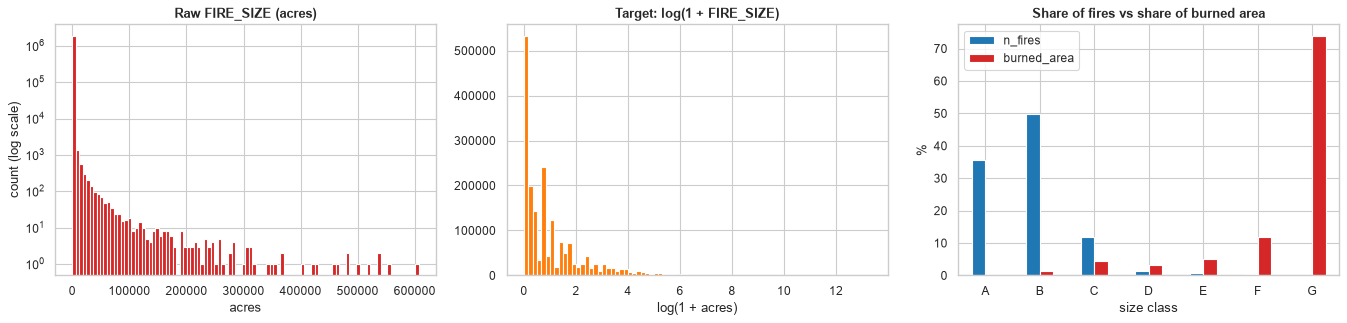

SIZE_CLASS,A,B,C,D,E,F,G
n_fires,35.4700,49.9500,11.7100,1.5100,0.7500,0.4100,0.2000
burned_area,0.0600,1.4400,4.4800,3.2800,5.1600,11.8400,73.7400


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].hist(df["FIRE_SIZE"], bins=100, color="tab:red")
axes[0].set(yscale="log", title="Raw FIRE_SIZE (acres)", xlabel="acres", ylabel="count (log scale)")
axes[1].hist(df["LOG_SIZE"], bins=80, color="tab:orange")
axes[1].set(title="Target: log(1 + FIRE_SIZE)", xlabel="log(1 + acres)")

by_class = df.groupby("SIZE_CLASS")["FIRE_SIZE"].agg(n_fires="size", burned_area="sum")
share = 100 * by_class / by_class.sum()
share.plot.bar(ax=axes[2], color=["tab:blue", "tab:red"], rot=0)
axes[2].set(title="Share of fires vs share of burned area", ylabel="%", xlabel="size class")
plt.tight_layout()
plt.show()
share.T.round(2)

Observations:
* 85 % of fires are class A or B (< 10 acres), but they burn only 1.5 % of the total area. The 0.2 % of fires in class G (≥ 5,000 acres) burn 74 % of it. This is a typical heavy-tailed phenomenon: a few giant fires dominate.
* On the raw scale, a model minimising squared error would only care about these few giant fires. The log transform brings the target onto a scale where every fire counts, and the errors become ratios ("off by a factor of 2").
* Even in log space the distribution is very skewed, with a mass near 0, and it has spikes: sizes are rounded by the people who report them (0.1 acre: 459 k fires, 1 acre: 221 k, 0.5 acre: 113 k). This rounding noise caps the achievable precision for small fires.

### 5.2 Missing values are *not* random
A common shortcut is `df.dropna()`: drop every row with a missing value. The containment date is missing for half of the fires and `COUNTY` for a third of them, so this would remove most of the data. Before doing anything like that, we check whether the missing values are random: if they are not, dropping them changes the problem we solve.

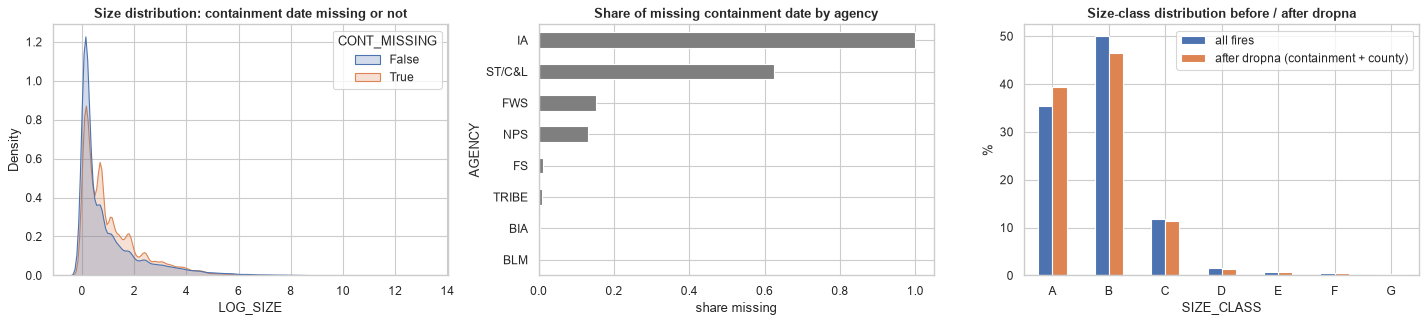

,count,mean,std,min,50%,90%,99%,max
CONT_MISSING,,,,,,,,
False,988836.0000,119.2799,3374.8031,0.0001,0.5000,17.0000,817.0000,606945.0000
True,890855.0000,24.9004,721.7100,0.0000,1.0000,16.4000,247.0000,234000.0000


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
sns.kdeplot(data=df.sample(200_000, random_state=RANDOM_STATE), x="LOG_SIZE", hue="CONT_MISSING",
            common_norm=False, ax=axes[0], fill=True)
axes[0].set_title("Size distribution: containment date missing or not")

missing_by_agency = df.groupby("AGENCY")["CONT_MISSING"].agg(["mean", "size"]).query("size > 1000")
missing_by_agency["mean"].sort_values().plot.barh(ax=axes[1], color="tab:gray")
axes[1].set(title="Share of missing containment date by agency", xlabel="share missing")

compare = pd.DataFrame({
    "all fires": df["SIZE_CLASS"].value_counts(normalize=True),
    "after dropna (containment + county)": df.loc[~df["CONT_MISSING"] & ~df["COUNTY_MISSING"], "SIZE_CLASS"].value_counts(normalize=True),
}).sort_index() * 100
compare.plot.bar(ax=axes[2], rot=0)
axes[2].set(title="Size-class distribution before / after dropna", ylabel="%")
plt.tight_layout()
plt.show()
df.groupby("CONT_MISSING")["FIRE_SIZE"].describe(percentiles=[0.5, 0.9, 0.99])

Observations:
* The containment date is missing for 47 % of fires, and not at random: the gap comes from the *reporting system* (100 % missing for interagency `IA` reports, 62 % for state/local `ST/C&L`, ~0 % for the Forest Service or BLM).
* Fires without a containment date have a higher median (1 vs 0.5 acre) but a much lighter tail (99th percentile 247 vs 817 acres, mean 25 vs 119).
* A `dropna` on containment date and county would therefore change the population: class A goes from 35 % to 39 %, and mostly state/local (East and South) fires are removed. A model trained on that subset learns a different problem from the one we actually want to solve.
* → We keep every fire in Scenario A. Scenario B is, by construction, restricted to fires with a valid duration (52.6 %), and we keep in mind that this subset is biased.

### 5.3 Time: years, seasons, hours

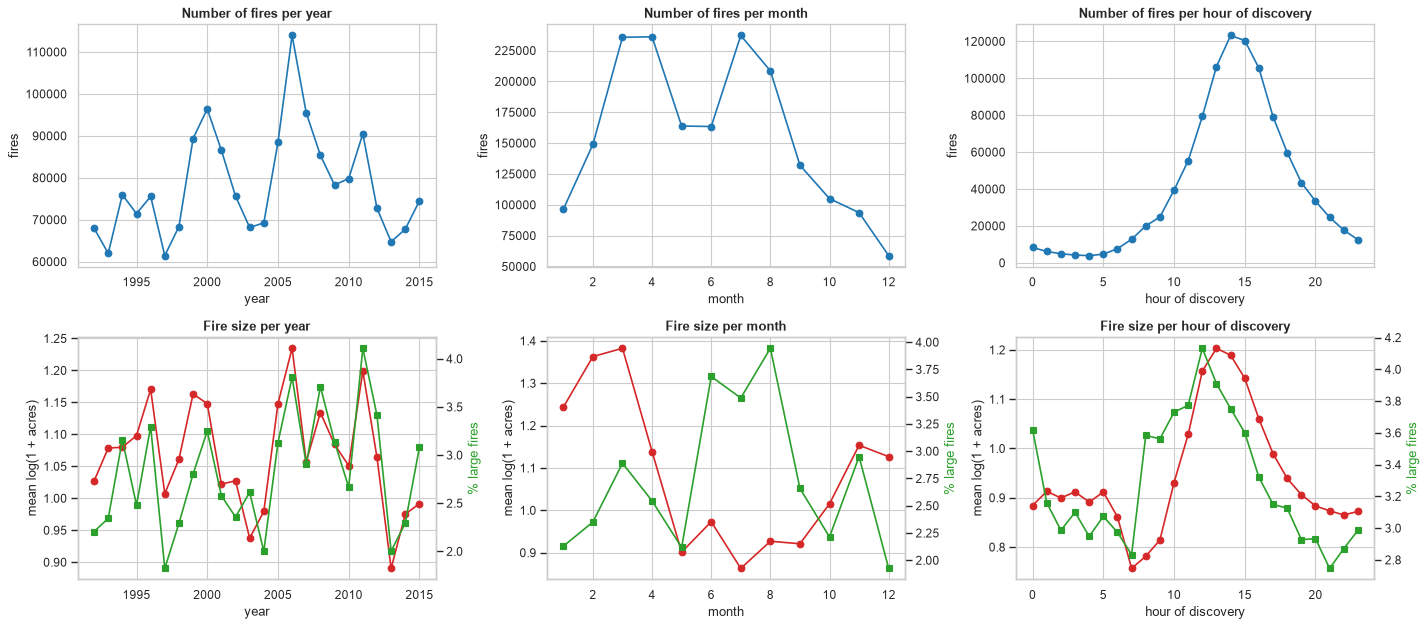

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, col, title in zip(axes[0], ["FIRE_YEAR", "MONTH", "DISC_HOUR"], ["year", "month", "hour of discovery"]):
    key = np.floor(df[col]) if col == "DISC_HOUR" else df[col]
    df.groupby(key).size().plot(ax=ax, marker="o", color="tab:blue")
    ax.set(title=f"Number of fires per {title}", xlabel=title, ylabel="fires")
for ax, col, title in zip(axes[1], ["FIRE_YEAR", "MONTH", "DISC_HOUR"], ["year", "month", "hour of discovery"]):
    key = np.floor(df[col]) if col == "DISC_HOUR" else df[col]
    grouped = df.groupby(key)
    grouped["LOG_SIZE"].mean().plot(ax=ax, marker="o", color="tab:red", label="mean log size")
    ax2 = ax.twinx()
    (100 * grouped["FIRE_SIZE"].apply(lambda s: (s >= 100).mean())).plot(ax=ax2, marker="s", color="tab:green",
                                                                          label="% large (>= 100 ac)")
    ax2.grid(False)
    ax.set(title=f"Fire size per {title}", xlabel=title, ylabel="mean log(1 + acres)")
    ax2.set_ylabel("% large fires", color="tab:green")
plt.tight_layout()
plt.show()

Observations:
* Years: 61 k to 114 k fires per year, with no clear trend in size. Year is a weak feature, which is good news for predicting future years.
* Months: two fire seasons. Spring (March–April) has the most fires and the largest average size: dry grass before green-up, debris burning. Summer (July–August) has a second peak in count, but the share of large fires peaks in June–August (≈ 3.7–3.9 %). There are two regimes: many medium-sized spring fires, and rarer but huge summer fires.
* Hour of discovery: fires discovered between 12:00 and 15:00 are the largest on average (peak burning conditions: highest temperature, lowest humidity). Morning fires (7–9 am) are the smallest. Night-time counts are small, so those points are noisy.
* Weekday has no visible effect (confirmed in Section 6).

### 5.4 Causes, seasons and land owners

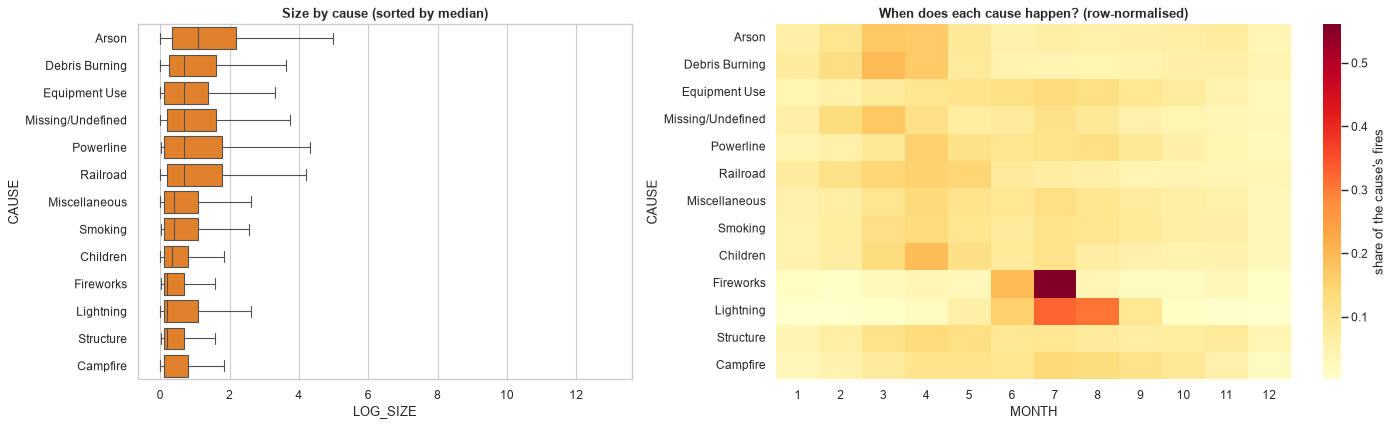

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})
cause_order = df.groupby("CAUSE")["LOG_SIZE"].median().sort_values(ascending=False).index
sns.boxplot(data=df.sample(300_000, random_state=RANDOM_STATE), y="CAUSE", x="LOG_SIZE", order=cause_order,
            ax=axes[0], fliersize=0, color="tab:orange")
axes[0].set_title("Size by cause (sorted by median)")

cause_month = pd.crosstab(df["CAUSE"], df["MONTH"], normalize="index").loc[cause_order]
sns.heatmap(cause_month, cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "share of the cause's fires"})
axes[1].set_title("When does each cause happen? (row-normalised)")
plt.tight_layout()
plt.show()

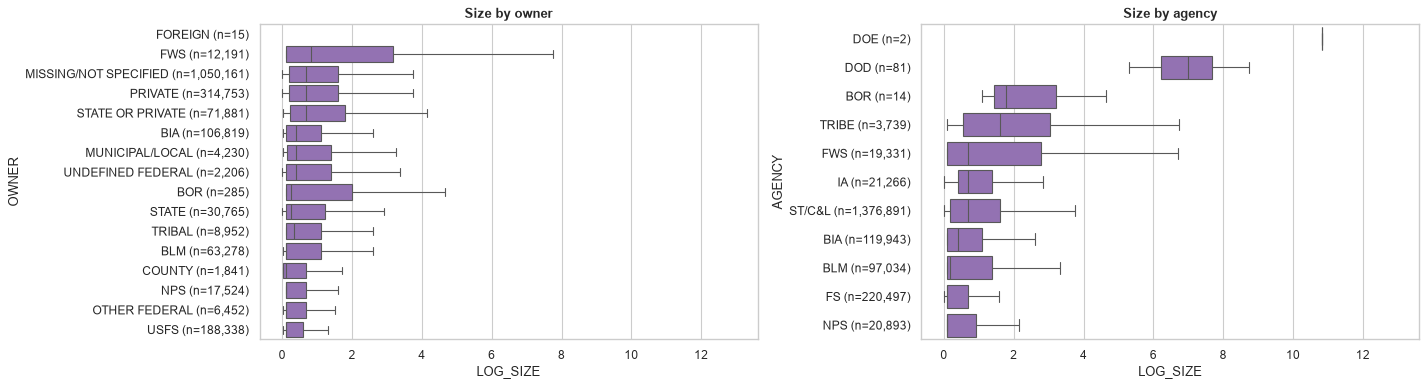

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
sample = df.sample(300_000, random_state=RANDOM_STATE)
for ax, col in zip(axes, ["OWNER", "AGENCY"]):
    order = df.groupby(col)["LOG_SIZE"].median().sort_values(ascending=False).index
    sns.boxplot(data=sample, y=col, x="LOG_SIZE", order=order, ax=ax, fliersize=0, color="tab:purple")
    counts = df[col].value_counts()
    ax.set_yticks(range(len(order)), [f"{o} (n={counts[o]:,})" for o in order])
    ax.set_title(f"Size by {col.lower()}")
plt.tight_layout()
plt.show()

Observations:
* Cause × month shows very clear seasonal patterns: fireworks fires happen almost only in early July (Independence Day), lightning in June–August, while debris burning, arson and children peak in March–April.
* Cause vs size: arson, debris burning, powerline and railroad fires have the highest *median* size. Lightning has one of the lowest medians, yet it accounts for 29 % of all large fires and 62 % of the total burned area: lightning starts fires in remote western areas where they are found late and spread far. The median hides the tail, which is exactly why the target needs a log scale and tail-aware metrics.
* Owner / agency: fires on land managed by the Fish & Wildlife Service (FWS, refuges in Alaska and Florida marshes) or the Department of Defense are large (but DOD has only 81 fires). Federal agencies (USFS, NPS) record many tiny fires that local reporting would never log. So these features also encode reporting practices, not only physics.

### 5.5 Space: where fires happen vs where they get big

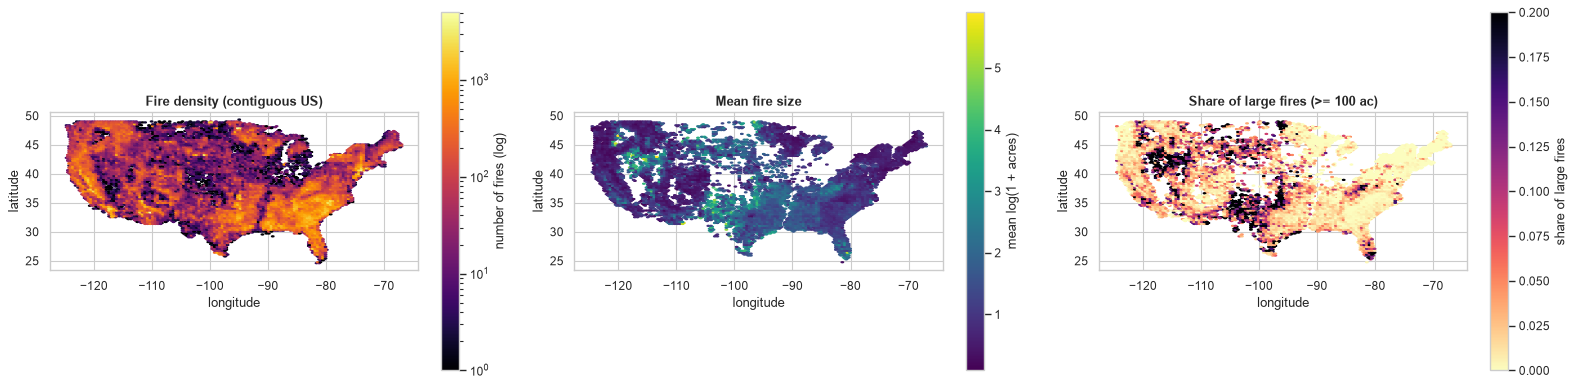

In [14]:
conus = df[df["LONGITUDE"].between(-125, -66) & df["LATITUDE"].between(24, 50)]
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
hb = axes[0].hexbin(conus["LONGITUDE"], conus["LATITUDE"], gridsize=130, bins="log", cmap="inferno", mincnt=1)
fig.colorbar(hb, ax=axes[0], label="number of fires (log)")
axes[0].set_title("Fire density (contiguous US)")
hb = axes[1].hexbin(conus["LONGITUDE"], conus["LATITUDE"], C=conus["LOG_SIZE"], reduce_C_function=np.mean,
                    gridsize=130, cmap="viridis", mincnt=20)
fig.colorbar(hb, ax=axes[1], label="mean log(1 + acres)")
axes[1].set_title("Mean fire size")
hb = axes[2].hexbin(conus["LONGITUDE"], conus["LATITUDE"], C=(conus["FIRE_SIZE"] >= 100).astype(float),
                    reduce_C_function=np.mean, gridsize=130, cmap="magma_r", mincnt=20, vmax=0.2)
fig.colorbar(hb, ax=axes[2], label="share of large fires")
axes[2].set_title("Share of large fires (>= 100 ac)")
for ax in axes:
    ax.set(xlabel="longitude", ylabel="latitude", aspect="equal")
plt.tight_layout()
plt.show()

Observations:
* Where fires happen is not where they get big. Fire *density* is highest in the Southeast (Georgia, the Carolinas, Florida), in California and along the Appalachians. *Large* fires are concentrated in the West and the Great Plains (dry grassland, shrubland and rangeland). 51 % of large fires happen west of −100° longitude, which holds only 34 % of all fires.
* There is a sharp change around −100° longitude (the arid/humid divide of the US). A tree model can learn this kind of threshold easily; a linear model cannot.
* This motivates the grid-cell target encoding (the historical fire regime of each 0.5° cell) and suggests that location will be the strongest feature group (confirmed in Sections 6 and 12).

### 5.6 Duration vs size (Scenario B only)

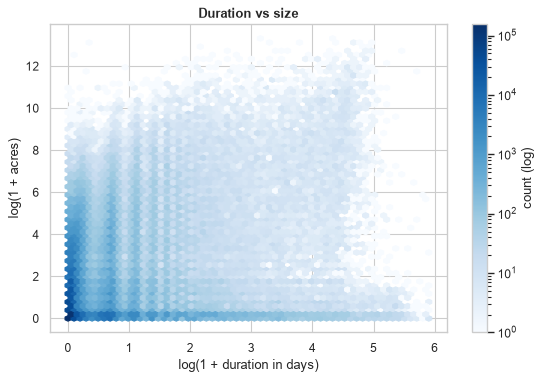

Spearman(duration, size) = 0.160
Fires contained the same day: 88.0%


In [15]:
with_duration = df.dropna(subset=["DURATION_DAYS"])
fig, ax = plt.subplots(figsize=(8, 5))
hb = ax.hexbin(np.log1p(with_duration["DURATION_DAYS"]), with_duration["LOG_SIZE"], gridsize=60, bins="log", cmap="Blues")
fig.colorbar(hb, label="count (log)")
ax.set(xlabel="log(1 + duration in days)", ylabel="log(1 + acres)", title="Duration vs size")
plt.show()
print(f"Spearman(duration, size) = {with_duration[['DURATION_DAYS', 'LOG_SIZE']].corr('spearman').iloc[0, 1]:.3f}")
print(f"Fires contained the same day: {(with_duration['DURATION_DAYS'] < 1).mean():.1%}")

Observations:
* 88 % of fires are contained within a day. The Spearman correlation between duration and size is only 0.16 overall. There are many long but tiny fires (smouldering fires, or records that were closed late), and some huge fires contained quickly (fast grass fires).
* Duration alone is therefore a weak predictor, but combined with location it becomes very informative (Section 12). Above all, it is not available at discovery time, so it is only used in Scenario B.

## 6. Correlations & feature relevance
Why not a simple Pearson correlation matrix? Pearson measures *linear* relations and is dominated by extreme values: computed on the raw `FIRE_SIZE`, a few 500,000-acre fires decide the result, and every correlation comes out close to zero. It also does not apply to categorical features (cause, state, reporting unit), which are most of our inputs. No single measure fits every feature type, so we use three complementary ones:
* Spearman ρ between numeric features and the target: rank-based, so it is robust to the heavy tail and captures any *monotonic* relation.
* Correlation ratio η² for categorical features: the share of the target variance explained by the category means (a "one-way ANOVA R²").
* Mutual information: captures *any* dependency (including non-monotonic ones like latitude or hour), for all features on the same scale.

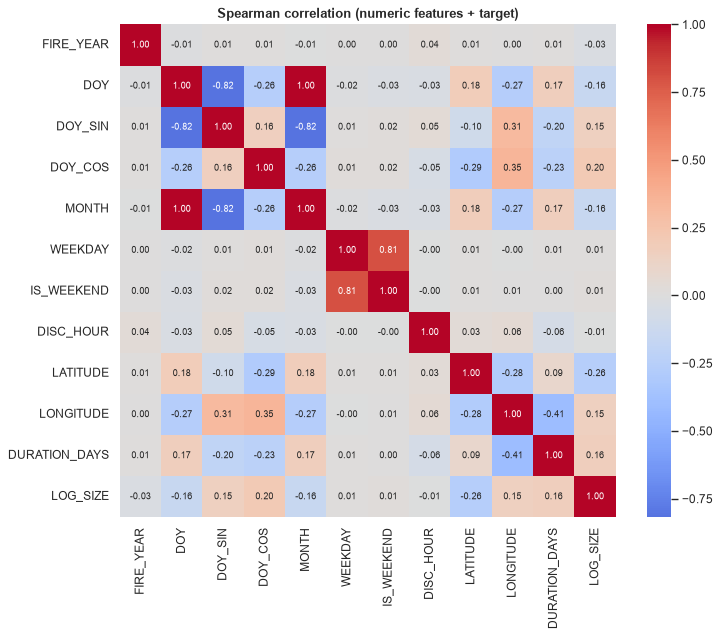

In [16]:
numeric_cols = [c for c in FEATURES_B if c not in LOW_CARD_CATEGORICAL + HIGH_CARD_CATEGORICAL]
spearman = df[numeric_cols + [TARGET]].sample(400_000, random_state=RANDOM_STATE).corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(spearman, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=ax, annot_kws={"size": 8})
ax.set_title("Spearman correlation (numeric features + target)")
plt.show()

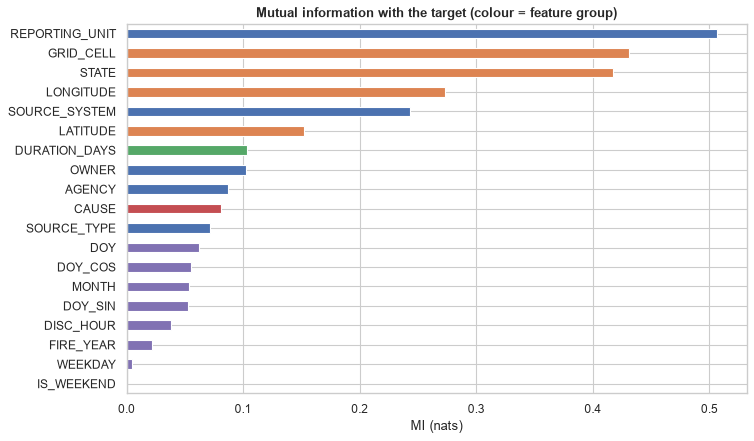

,group,spearman_rho,eta2,mutual_info
REPORTING_UNIT,reporting,NaN,0.1739,0.5065
GRID_CELL,space,NaN,0.2105,0.4308
STATE,space,NaN,0.1120,0.4172
LONGITUDE,space,0.1511,NaN,0.2728
SOURCE_SYSTEM,reporting,NaN,0.0640,0.2434
LATITUDE,space,-0.2613,NaN,0.1519
DURATION_DAYS,post-event (B),0.1629,NaN,0.1031
OWNER,reporting,NaN,0.0142,0.1027
AGENCY,reporting,NaN,0.0141,0.0872
CAUSE,cause,NaN,0.0238,0.0808


In [17]:
def correlation_ratio(categories, values):
    """eta^2 = between-group variance / total variance (0: no link, 1: categories determine the value)."""
    groups = values.groupby(categories, observed=True)
    between = (groups.size() * (groups.mean() - values.mean()) ** 2).sum()
    return between / ((values - values.mean()) ** 2).sum()


mi_sample = df.sample(60_000, random_state=RANDOM_STATE)
mi_X = mi_sample[FEATURES_B].copy()
categorical_all = LOW_CARD_CATEGORICAL + HIGH_CARD_CATEGORICAL
mi_X[categorical_all] = OrdinalEncoder().fit_transform(mi_X[categorical_all])
mi_X = mi_X.fillna(-1)
mi = mutual_info_regression(mi_X, mi_sample[TARGET], discrete_features=[c in categorical_all for c in mi_X.columns],
                            random_state=RANDOM_STATE)

relevance = pd.DataFrame({
    "group": [next((g for g, fs in FEATURE_GROUPS.items() if f in fs), "post-event (B)") for f in FEATURES_B],
    "spearman_rho": [spearman.loc[f, TARGET] if f in numeric_cols else np.nan for f in FEATURES_B],
    "eta2": [correlation_ratio(df[f], df[TARGET]) if f in categorical_all else np.nan for f in FEATURES_B],
    "mutual_info": mi,
}, index=FEATURES_B).sort_values("mutual_info", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
relevance["mutual_info"].plot.barh(ax=ax, color=[sns.color_palette()[list(relevance["group"].unique()).index(g)]
                                                  for g in relevance["group"]])
ax.invert_yaxis()
ax.set(title="Mutual information with the target (colour = feature group)", xlabel="MI (nats)")
plt.show()
relevance

Observations:
* No single feature determines the size. The strongest numeric association is with latitude (ρ = −0.26: southern fires are bigger), and the largest η² is the grid cell (0.21). This confirms the task is not trivial and that no leakage is left.
* Location dominates. By mutual information, the reporting unit, grid cell, state, longitude and source system come first. Note that MI is biased upwards for features with many categories (reporting unit: 1,640; grid cell: 4,323), so their rank should be read with caution. The ablation (Section 12) gives a more reliable ranking.
* Redundancy: `DOY` and `MONTH` are perfectly rank-correlated, and `WEEKDAY`/`IS_WEEKEND` carry almost nothing. We keep them because trees ignore useless features, and the ablation measures the time group as a whole.
* Time features have low *linear* correlations but non-zero MI: their effect is non-monotonic (two seasons, a daily cycle), which a correlation coefficient cannot see.

## 7. Train / validation / test protocol

We use a temporal split:
* Train: 1992–2011. Validation: 2012–2013 (model selection and tuning). Test: 2014–2015 (touched once, at the very end).

Why not a random split? Fires that happen on the same day in the same area (lightning storms, fire complexes) are strongly correlated. With a random split, the model sees "neighbours" of every test fire during training, and the score is optimistic. Predicting future years is also what a real deployment would do. Koh (2023) reports the same thing on this kind of data. We quantify the gap in Section 14.

Why two years each for validation and test? One year can be unusual (a very wet or very dry season); two years give a more stable estimate while keeping 20 years of history for training.

To compare many models quickly and fairly, Sections 9–12 train on the same random subsample of 300 k training fires. Training a model on 1.6 M fires takes minutes, and we fit more than 100 models in this notebook. The subsample keeps every experiment comparable, and the learning curve (Section 10.3) checks afterwards what the full training set adds. The final model (Section 13) is retrained on all training + validation years.

In [18]:
train_df = df[df["FIRE_YEAR"] <= 2011]
val_df = df[df["FIRE_YEAR"].between(2012, 2013)]
test_df = df[df["FIRE_YEAR"] >= 2014]
train_sub = train_df.sample(300_000, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    name: {"years": f"{part['FIRE_YEAR'].min()}-{part['FIRE_YEAR'].max()}", "n_fires": len(part),
           "mean_log_size": part[TARGET].mean(), "% large (>=100 ac)": 100 * (part["FIRE_SIZE"] >= 100).mean(),
           "% with duration": 100 * part["DURATION_DAYS"].notna().mean(),
           "% cause missing": 100 * (part["CAUSE"] == "Missing/Undefined").mean()}
    for name, part in [("train", train_df), ("train_sub", train_sub), ("validation", val_df), ("test", test_df)]
}).T
split_summary

,years,n_fires,mean_log_size,% large (>=100 ac),% with duration,% cause missing
train,1992-2011,1599959,1.0936,2.9042,47.9472,9.2621
train_sub,1992-2011,300000,1.0949,2.9593,47.8033,9.2810
validation,2012-2013,137499,0.9822,2.7491,77.8282,5.8000
test,2014-2015,142233,0.9837,2.7047,80.5643,7.0131


Observations:
* Train: 1.60 M fires, validation: 137 k, test: 142 k. The 300 k subsample is representative of the training set (same mean size and same share of large fires).
* The distribution shifts over time: validation and test fires are smaller on average (mean log size 0.98 vs 1.09), and the share of fires with a recorded duration jumps from 48 % to 78–81 %. Reporting practices evolve, which is exactly what a temporal split exposes and a random split hides.

## 8. Preprocessing pipelines

Why pipelines? Every transformation that learns something from the data (a median, a scaling factor, the mean size per grid cell) must be learned on the training fires only. Otherwise information from the validation or test years leaks into the model. An sklearn `Pipeline` guarantees this: `fit` learns the encoders and the model on the training data, `predict` only applies them. It also means every model gets *exactly* the same features, and the code is written once instead of being repeated in every cell.

Different model families need different input representations. We build them with a single function:

| | Tree models (`kind="tree"`) | Linear / distance / neural models (`kind="dense"`) |
|---|---|---|
| numeric | passed as is (NaN kept, trees handle it) | median imputation + missing indicator + standardisation |
| low-cardinality categorical | ordinal codes (HistGradientBoosting uses them as native categories) | one-hot encoding (rare categories < 100 fires grouped) |
| high-cardinality categorical (grid cell, reporting unit) | target encoding (cross-fitted, to avoid leakage) + log-frequency (historical fire activity) | same, then standardised |

Why these choices?
* Trees do not need scaling (a split threshold does not care about units) and can handle NaN and categories directly. Linear, k-NN and neural models do need scaled numbers: k-NN measures distances, and Ridge/MLP need comparable scales for their weights and gradients.
* Missing indicator: missingness carries information here (Section 5.2: whether a value is missing depends on the reporting system, which is itself related to fire size), so linear models get a 0/1 flag in addition to the imputed value.
* Why not one-hot for the reporting unit (1,640 values) and the grid cell (4,323)? That would create ~6,000 sparse columns, mostly for categories with very few fires, whose coefficients would be pure noise. Target encoding compresses each of them into one number, "the typical (log) size of past fires here", and its smoothing pulls rare categories towards the global mean. The frequency encoding adds "how many fires were reported here": busy, well-monitored areas report many small fires.

Target encoding replaces a category by the (smoothed) mean target of that category in the training data. sklearn's `TargetEncoder` uses internal cross-fitting during `fit_transform`, so a training row never sees its own target. This is how the grid cell becomes "the typical fire size at this location in the past".

⚠️ Subtlety when measuring the training score. Because of this cross-fitting, a training row is encoded differently during `fit` (out-of-fold mean) and during `predict` (mean over all training rows). If we simply call `model.predict(X_train)`, we evaluate the model on inputs it has never seen, and the "train R²" comes out far too low (a naive `predict` gives a train R² of only 0.3 for a depth-30 tree, which is impossible for a tree that deep). Our helper therefore scores the training rows on exactly the encoding the model was fitted on.

In [19]:
class FrequencyEncoder(BaseEstimator, TransformerMixin):
    """Replace each category by log(1 + number of training rows with that category)."""

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.columns_ = list(X.columns)
        self.counts_ = {c: X[c].value_counts() for c in self.columns_}
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.columns_)
        return np.column_stack([np.log1p(X[c].map(self.counts_[c]).astype(float).fillna(0).to_numpy())
                                for c in self.columns_])

    def get_feature_names_out(self, input_features=None):
        return np.array([f"{c}_logfreq" for c in self.columns_])


def make_preprocessor(features, kind):
    numeric = [f for f in features if f not in LOW_CARD_CATEGORICAL + HIGH_CARD_CATEGORICAL]
    low_card = [f for f in features if f in LOW_CARD_CATEGORICAL]
    high_card = [f for f in features if f in HIGH_CARD_CATEGORICAL]
    target_encoder = TargetEncoder(target_type="auto", cv=KFold(5, shuffle=True, random_state=RANDOM_STATE))
    if kind == "tree":
        transformers = [
            ("num", "passthrough", numeric),
            ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), low_card),
            ("te", target_encoder, high_card),
            ("freq", FrequencyEncoder(), high_card),
        ]
    else:
        transformers = [
            ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), numeric),
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False), low_card),
            ("te", make_pipeline(target_encoder, StandardScaler()), high_card),
            ("freq", make_pipeline(FrequencyEncoder(), StandardScaler()), high_card),
        ]
    preprocessor = ColumnTransformer([t for t in transformers if t[2]])
    return preprocessor.set_output(transform="pandas") if kind == "tree" else preprocessor


def make_model(features, estimator, kind):
    return Pipeline([("prep", make_preprocessor(features, kind)), ("model", estimator)])


HGB_DEFAULTS = dict(max_iter=500, early_stopping=True, n_iter_no_change=20, random_state=RANDOM_STATE)


def make_hgb(features, classifier=False, **params):
    """HistGradientBoosting with native categorical support for the low-cardinality features."""
    categorical = [f"cat__{f}" for f in features if f in LOW_CARD_CATEGORICAL] or None
    estimator_class = HistGradientBoostingClassifier if classifier else HistGradientBoostingRegressor
    return make_model(features, estimator_class(categorical_features=categorical, **{**HGB_DEFAULTS, **params}), "tree")


dense_preview = make_preprocessor(FEATURES_A, "dense").fit(train_sub[FEATURES_A], train_sub[TARGET])
tree_preview = make_preprocessor(FEATURES_A, "tree").fit(train_sub[FEATURES_A], train_sub[TARGET])
print(f"{len(FEATURES_A)} raw features -> {len(dense_preview.get_feature_names_out())} columns for dense models, "
      f"{len(tree_preview.get_feature_names_out())} columns for tree models")

18 raw features -> 140 columns for dense models, 20 columns for tree models


### Evaluation helpers
Every model is evaluated by the same two functions. `regression_report` computes all metrics at once, and `fit_and_evaluate` also reports the training score and the training time. The train score is what tells us whether a model *underfits* (train and validation both low) or *overfits* (train high, validation low).

In [20]:
def regression_report(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "class_acc": np.mean(to_size_class(np.expm1(y_true)) == to_size_class(np.expm1(np.clip(y_pred, 0, None)))),
    }


def fit_and_evaluate(name, model, train, val, features, train_eval_size=50_000):
    start = time.perf_counter()
    model.fit(train[features], train[TARGET])
    fit_seconds = time.perf_counter() - start
    # Train score on the cross-fitted encoding seen during fit (fit_transform is deterministic: same folds, same data)
    X_seen = model["prep"].fit_transform(train[features], train[TARGET])
    rows = np.random.default_rng(RANDOM_STATE).choice(len(train), min(train_eval_size, len(train)), replace=False)
    X_seen = X_seen.iloc[rows] if hasattr(X_seen, "iloc") else X_seen[rows]
    return {
        "model": name,
        **regression_report(val[TARGET], model.predict(val[features])),
        "R2_train": r2_score(train[TARGET].iloc[rows], model["model"].predict(X_seen)),
        "fit_seconds": fit_seconds,
    }

## 9. Model comparison (Scenario A, at discovery)

All models get the same 300 k training fires and are scored on the full validation set (2012–2013). We go from the simplest to the most flexible:

* Mean baseline: predicts the training mean (R² = 0 by definition). Every model must beat it.
* Ridge: linear regression with L2 regularisation. Can only add up feature effects.
* k-NN: predicts the mean size of the k most similar fires. Purely local, no training, sensitive to the scaling of the features.
* Decision tree: non-linear, interpretable, but high variance.
* Random forest: average of many decorrelated deep trees (bagging), which reduces variance.
* MLP: a small neural network (2 hidden layers) with early stopping.
* HistGradientBoosting: trees added sequentially, each one fixing the errors of the previous ones (boosting), with histogram binning so it scales to millions of rows. This is the SOTA reference.

Why this list? Each model tests a hypothesis about the data. *Is the relation additive?* (Ridge). *Do similar fires have similar sizes?* (k-NN). *Are there thresholds and interactions?* (trees). *Does averaging many trees reduce the noise?* (random forest). *Does a flexible non-tree model do as well?* (MLP). *Does sequential error correction do better?* (boosting). We do not use kernel SVMs: their training cost grows with the square of the number of rows, which is impractical beyond a few tens of thousands of fires.

In [21]:
candidates = {
    "Mean baseline": ("dense", DummyRegressor()),
    "Ridge": ("dense", Ridge(alpha=1.0)),
    "k-NN (k=50)": ("dense", KNeighborsRegressor(n_neighbors=50, n_jobs=-1)),
    "Decision tree (depth 12)": ("tree", DecisionTreeRegressor(max_depth=12, min_samples_leaf=50, random_state=RANDOM_STATE)),
    "Random forest": ("tree", RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features=0.5,
                                                    n_jobs=-1, random_state=RANDOM_STATE)),
    "MLP (128-64)": ("dense", MLPRegressor(hidden_layer_sizes=(128, 64), early_stopping=True, max_iter=60,
                                           batch_size=512, random_state=RANDOM_STATE)),
}
comparison = []
for name, (kind, estimator) in candidates.items():
    comparison.append(fit_and_evaluate(name, make_model(FEATURES_A, estimator, kind), train_sub, val_df, FEATURES_A))
    print(f"{name:<28} done: val R2 = {comparison[-1]['R2']:.4f} ({comparison[-1]['fit_seconds']:.0f}s)")
hgb_default = make_hgb(FEATURES_A)
comparison.append(fit_and_evaluate("HistGradientBoosting (default)", hgb_default, train_sub, val_df, FEATURES_A))
comparison = pd.DataFrame(comparison).set_index("model")
comparison

Mean baseline                done: val R2 = -0.0071 (2s)


Ridge                        done: val R2 = 0.1617 (2s)


k-NN (k=50)                  done: val R2 = 0.1859 (2s)


Decision tree (depth 12)     done: val R2 = 0.1251 (3s)


Random forest                done: val R2 = 0.1572 (15s)


MLP (128-64)                 done: val R2 = 0.1822 (32s)


,R2,RMSE,MAE,class_acc,R2_train,fit_seconds
model,,,,,,
Mean baseline,-0.0071,1.3429,0.9728,0.4697,-0.0000,1.6816
Ridge,0.1617,1.2252,0.8459,0.4886,0.2224,1.7906
k-NN (k=50),0.1859,1.2074,0.8009,0.4921,0.2644,1.5626
Decision tree (depth 12),0.1251,1.2517,0.8421,0.4909,0.2575,2.5443
Random forest,0.1572,1.2285,0.8420,0.4895,0.6148,14.9391
MLP (128-64),0.1822,1.2101,0.8256,0.4967,0.2802,32.1878
HistGradientBoosting (default),0.1883,1.2056,0.8053,0.5058,0.3484,12.7145


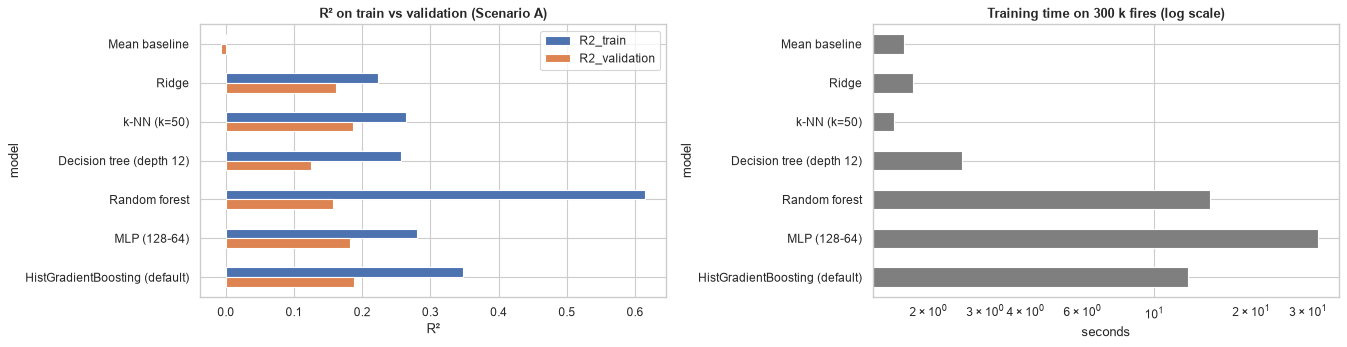

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
comparison[["R2_train", "R2"]].rename(columns={"R2": "R2_validation"}).plot.barh(ax=axes[0])
axes[0].set(title="R² on train vs validation (Scenario A)", xlabel="R²")
axes[0].invert_yaxis()
comparison["fit_seconds"].plot.barh(ax=axes[1], color="tab:gray", logx=True)
axes[1].set(title="Training time on 300 k fires (log scale)", xlabel="seconds")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

Observations:
* Every model beats the mean baseline, but none by much: the best validation R² is 0.188 (default HistGradientBoosting). With only the information available at discovery, most of the variance of the final size cannot be predicted (wind, fuel moisture and response time are not in the data).
* Ranking on validation: gradient boosting 0.188, k-NN 0.186, MLP 0.182, Ridge 0.162, random forest 0.157, single tree 0.125.
* How to read train vs validation. Ridge has only ~140 coefficients for 300 k fires, so it cannot overfit, yet its train R² (0.222) is 0.06 above its validation R² (0.162). This gap comes from the change between the training years and the validation years (Section 7), not from overfitting. Every model pays it, so a gap of about 0.06 is the "normal" level here.
* The random forest overfits: train R² 0.615 vs validation 0.157. With `min_samples_leaf=5`, its trees fit groups of 5 fires, so they learn the noise of the target (rounded sizes, random weather). Averaging 100 trees reduces the noise coming from the model, not the noise in the target. The single tree (depth 12) is in the same situation on a smaller scale (0.258 vs 0.125).
* k-NN is almost as good as boosting: fires that look alike (same place, same season, same reporting unit) have similar sizes. But it has to search the whole training set for every new fire, so it gets slower as the data grows, and it has essentially one hyperparameter (k). It is not a good basis for a model trained on 1.6 M fires.
* The MLP (0.182) is competitive but is the slowest model (32 s) and gains nothing over trees. This is the usual result on tabular data with many categorical features (Grinsztajn et al., 2022, *Why do tree-based models still outperform deep learning on tabular data?*).
* Gradient boosting has the best validation R², the best size-class accuracy (50.6 %), a moderate train/validation gap (0.348 vs 0.188), trains in 13 s and handles missing values and categories natively. This is why it is the model we tune in Section 10.

## 10. Hyperparameter tuning
Why tune? Default hyperparameters are generic. On a noisy target like ours, the right amount of regularisation (how much each tree or coefficient is allowed to follow individual fires) can make a large difference. We first look at the bias/variance trade-off on two simple models, then tune the best model of Section 9. Every choice is made on the validation years, never on the test years.

### 10.1 Bias / variance: the decision tree depth
The tree depth is the clearest example of the bias/variance trade-off: a shallow tree underfits (both scores low), a deep tree memorises the training set (train score goes up, validation score goes down).

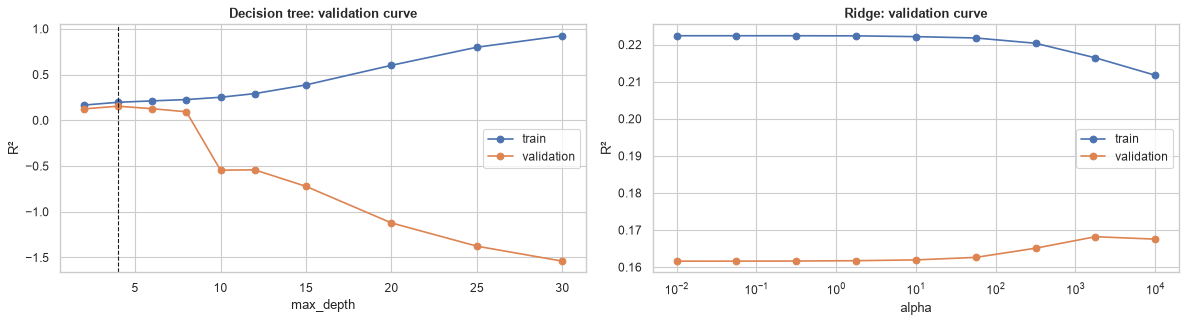

Best depth: 4 (val R2 = 0.1538)


In [23]:
depths = [2, 4, 6, 8, 10, 12, 15, 20, 25, 30]
depth_scores = []
for depth in depths:
    tree = make_model(FEATURES_A, DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE), "tree")
    result = fit_and_evaluate(f"depth {depth}", tree, train_sub, val_df, FEATURES_A)
    depth_scores.append({"max_depth": depth, "train": result["R2_train"], "validation": result["R2"]})
depth_scores = pd.DataFrame(depth_scores).set_index("max_depth")

alphas = np.logspace(-2, 4, 9)
ridge_scores = pd.DataFrame([
    {"alpha": a, **{k: v for k, v in fit_and_evaluate("", make_model(FEATURES_A, Ridge(alpha=a), "dense"),
                                                       train_sub, val_df, FEATURES_A).items() if k in ("R2", "R2_train")}}
    for a in alphas
]).set_index("alpha").rename(columns={"R2": "validation", "R2_train": "train"})

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
depth_scores.plot(ax=axes[0], marker="o")
axes[0].axvline(depth_scores["validation"].idxmax(), color="k", ls="--", lw=1)
axes[0].set(title="Decision tree: validation curve", ylabel="R²")
ridge_scores[["train", "validation"]].plot(ax=axes[1], marker="o", logx=True)
axes[1].set(title="Ridge: validation curve", ylabel="R²")
plt.tight_layout()
plt.show()
print(f"Best depth: {depth_scores['validation'].idxmax()} (val R2 = {depth_scores['validation'].max():.4f})")

Observations:
* Decision tree: from depth 2 to 8, train and validation scores stay low and close to each other (underfitting). The best validation R² is at depth 4 (0.154). From depth 10 on, the train R² keeps rising (0.92 at depth 30) while the validation R² collapses below zero (−0.54 at depth 10, −1.5 at depth 30). A deep tree isolates small groups of fires and predicts their exact sizes, which is pure noise for future fires. This is the textbook picture of overfitting.
* The depth-12 tree of Section 9 scored 0.125 instead of −0.54 only because it had `min_samples_leaf=50`. Forcing each leaf to average many fires is the most effective regularisation on this target, and it is the one the random search below relies on.
* Ridge: the curves are almost flat (validation from 0.162 to 0.168 at alpha ≈ 1,800). With 300 k fires for 140 columns, there are far more examples than coefficients, so regularisation barely matters. Ridge is limited by its bias (it can only add up effects, no thresholds or interactions), not by its variance. We still keep the best alpha for the final Ridge (Section 13).
* Why this matters for tuning: the flexible models must not be allowed to follow individual fires. This is why we search large values of `min_samples_leaf` and of the L2 penalty for gradient boosting.

### 10.2 Randomised search for HistGradientBoosting
We search 5 hyperparameters at the same time. Random search covers such a space more efficiently than a grid (Bergstra & Bengio, 2012), especially when only a few hyperparameters really matter. Each candidate is trained on the 300 k training subsample and scored on the validation years (`PredefinedSplit`), which is exactly the "predict the future" setting. We do not use the usual K-fold cross-validation: it shuffles fires from all years together, which is the optimistic random split we avoid since Section 7.

| hyperparameter | role | range searched |
|---|---|---|
| `learning_rate` | step size of each tree; smaller = more trees needed but smoother fit | log-uniform 0.03 – 0.3 |
| `max_leaf_nodes` | complexity of each tree (interactions) | 15 – 511 |
| `min_samples_leaf` | minimum fires per leaf (regularisation) | 10 – 2000 |
| `l2_regularization` | shrinks leaf values | log-uniform 1e-3 – 10 |
| `max_features` | share of features tried at each split (randomisation) | 0.3 – 1.0 |

The number of trees (`max_iter` ≤ 500) is set by early stopping on an internal 10 % validation fraction: training stops when 20 more trees do not improve the score, which avoids tuning the number of trees separately and saves time.

In [24]:
search_data = pd.concat([train_sub, val_df])
predefined = PredefinedSplit(np.r_[np.full(len(train_sub), -1), np.zeros(len(val_df))])
param_distributions = {
    "model__learning_rate": loguniform(0.03, 0.3),
    "model__max_leaf_nodes": randint(15, 512),
    "model__min_samples_leaf": [10, 20, 50, 100, 200, 500, 1000, 2000],
    "model__l2_regularization": loguniform(1e-3, 10),
    "model__max_features": [0.3, 0.5, 0.7, 1.0],
}
search = RandomizedSearchCV(make_hgb(FEATURES_A), param_distributions, n_iter=16, cv=predefined, scoring="r2",
                            refit=False, random_state=RANDOM_STATE, n_jobs=1)
start = time.perf_counter()
search.fit(search_data[FEATURES_A], search_data[TARGET])
print(f"Search done in {time.perf_counter() - start:.0f}s")

search_results = pd.DataFrame(search.cv_results_["params"]).rename(columns=lambda c: c.replace("model__", ""))
search_results["val_R2"] = search.cv_results_["mean_test_score"]
search_results = search_results.sort_values("val_R2", ascending=False)
BEST_HGB_PARAMS = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
print("Best:", {k: round(v, 4) if isinstance(v, float) else v for k, v in BEST_HGB_PARAMS.items()})
search_results.head(8)

Search done in 969s
Best: {'l2_regularization': np.float64(0.0634), 'learning_rate': np.float64(0.0309), 'max_features': 0.3, 'max_leaf_nodes': 330, 'min_samples_leaf': 500}


,l2_regularization,learning_rate,max_features,max_leaf_nodes,min_samples_leaf,val_R2
9,0.0634,0.0309,0.3000,330,500,0.2160
5,0.0011,0.0316,0.7000,73,1000,0.2108
13,0.0177,0.0994,0.5000,274,500,0.2096
8,0.2342,0.0334,0.7000,149,200,0.2079
10,1.7123,0.0605,0.3000,400,100,0.2063
4,0.0053,0.0458,1.0000,328,500,0.2059
6,0.0036,0.0588,1.0000,285,500,0.2053
12,0.0049,0.0738,0.5000,374,100,0.2036


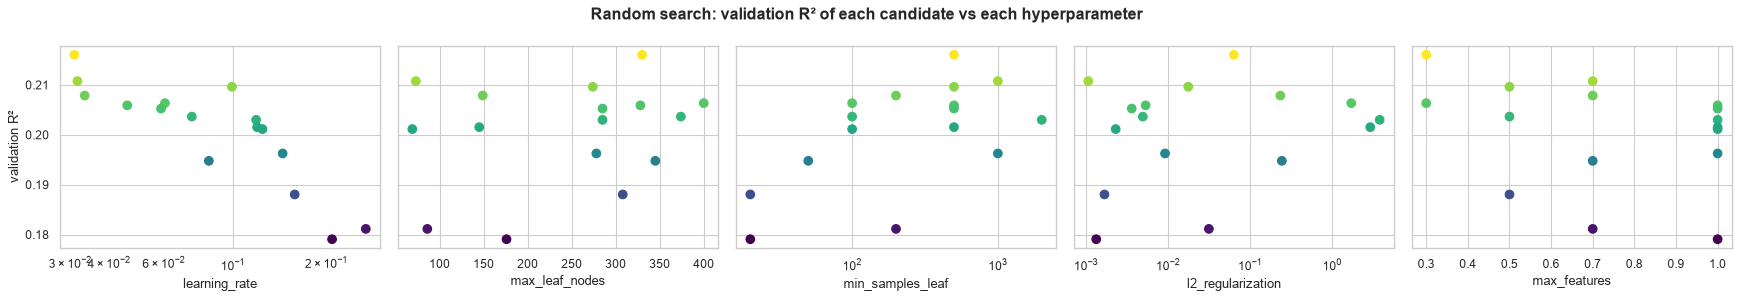

In [25]:
fig, axes = plt.subplots(1, 5, figsize=(22, 3.8), sharey=True)
for ax, param in zip(axes, ["learning_rate", "max_leaf_nodes", "min_samples_leaf", "l2_regularization", "max_features"]):
    ax.scatter(search_results[param], search_results["val_R2"], c=search_results["val_R2"], cmap="viridis", s=60)
    ax.set(xlabel=param, xscale="log" if param in ("learning_rate", "l2_regularization", "min_samples_leaf") else "linear")
axes[0].set_ylabel("validation R²")
fig.suptitle("Random search: validation R² of each candidate vs each hyperparameter", fontweight="bold")
plt.tight_layout()
plt.show()

Observations:
* Best candidate: `learning_rate` = 0.031, `max_leaf_nodes` = 330, `min_samples_leaf` = 500, `l2_regularization` = 0.063, `max_features` = 0.3. Validation R² = 0.216, vs 0.188 with default hyperparameters (+0.028 on the same data).
* What matters: a low learning rate (all the best candidates are < 0.1) and large leaves (`min_samples_leaf` ≥ 200). The target is very noisy (rounded sizes, unpredictable weather), so the model needs to average over many fires in each leaf. `max_leaf_nodes` and `l2_regularization` have little effect in this range. `max_features` < 1 (feature subsampling, as in random forests) helps a little.
* The best learning rate is at the lower edge of the range, and the model uses all 500 trees allowed. A smaller learning rate with more trees would probably gain a little more, at a higher compute cost.

### 10.3 Learning curve: do we need more data?
With the tuned hyperparameters, we train on increasing amounts of data, up to all 1.6 M training fires. If the validation score still goes up at the end, more data helps. If it has flattened, the limit is the information contained in the features, not the quantity of data.

n =    10,000: val R2 = 0.1284  train R2 = 0.2829  (7s, 448 trees)


n =    30,000: val R2 = 0.1572  train R2 = 0.3225  (22s, 472 trees)


n =   100,000: val R2 = 0.1975  train R2 = 0.3570  (77s, 500 trees)


n =   300,000: val R2 = 0.2160  train R2 = 0.3680  (138s, 500 trees)


n = 1,000,000: val R2 = 0.2264  train R2 = 0.3539  (145s, 500 trees)


n = 1,599,959: val R2 = 0.2269  train R2 = 0.3381  (154s, 500 trees)


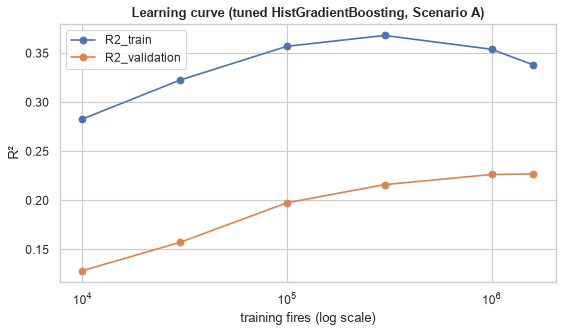

In [26]:
train_sizes = [10_000, 30_000, 100_000, 300_000, 1_000_000, len(train_df)]
learning_curve = []
for n in train_sizes:
    part = train_df.sample(n, random_state=RANDOM_STATE) if n < len(train_df) else train_df
    model_n = make_hgb(FEATURES_A, **BEST_HGB_PARAMS)
    learning_curve.append({"n_train": n, **fit_and_evaluate(f"{n}", model_n, part, val_df, FEATURES_A)})
    print(f"n = {n:>9,}: val R2 = {learning_curve[-1]['R2']:.4f}  train R2 = {learning_curve[-1]['R2_train']:.4f}  "
          f"({learning_curve[-1]['fit_seconds']:.0f}s, {model_n['model'].n_iter_} trees)")
learning_curve = pd.DataFrame(learning_curve).set_index("n_train")
hgb_full_train = model_n  # tuned model trained on all 1992-2011 fires

fig, ax = plt.subplots(figsize=(8, 4.2))
learning_curve[["R2_train", "R2"]].rename(columns={"R2": "R2_validation"}).plot(ax=ax, marker="o", logx=True)
ax.set(title="Learning curve (tuned HistGradientBoosting, Scenario A)", xlabel="training fires (log scale)", ylabel="R²")
plt.show()

Observations:
* The validation R² grows quickly up to 300 k fires (0.128 with 10 k, 0.198 with 100 k, 0.216 with 300 k), then flattens: 0.226 with 1 M and 0.227 with all 1.6 M fires. The last 600 k fires add only 0.0005.
* The training R² stays between 0.28 and 0.37, far from 1. The large leaves (at least 500 fires each) prevent the model from memorising individual fires. The train/validation gap shrinks from 0.15 (10 k) to 0.11 (1.6 M): more data reduces the variance.
* From 100 k fires on, the model uses all 500 trees allowed (early stopping never triggers). With a learning rate of 0.03, more trees might still add a little, but the flat validation curve shows that the main limit is the information contained in the features, not the number of fires. To go further we need new kinds of information (for example the weather at discovery), not more fires of the same kind.
* This also justifies the 300 k subsample used in Sections 9–12: it already reaches 95 % of the full-data score, at a fraction of the cost.

## 11. PCA: does dimensionality reduction help?

Why try PCA? After one-hot encoding, the dense representation has 140 columns, many of them correlated (DOY, MONTH and the cyclic encodings; four ways of describing location). Reducing them to a few uncorrelated components could remove noise, speed up training and help a linear model.

PCA finds the orthogonal directions of maximum variance in the (standardised, one-hot encoded) feature space. Three questions:
1. How many components do we need to keep most of the variance?
2. Do the first components separate small and large fires?
3. Does training on the PCA components help a linear model or a tree model?

PCA is unsupervised: it keeps the directions where the *features* vary most, which are not necessarily the directions that predict the *target*.

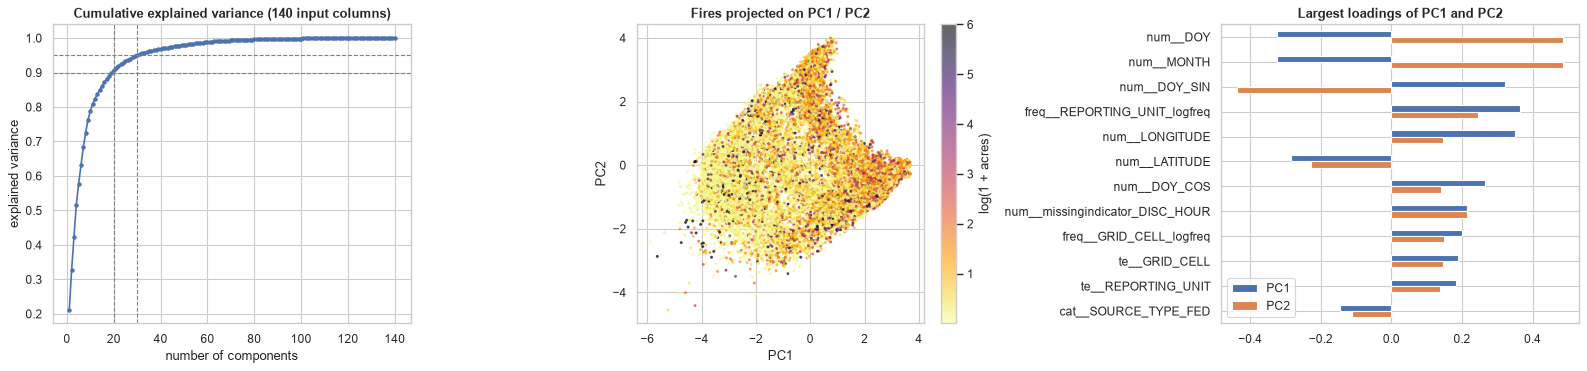

20 components keep 90% of the variance, 30 keep 95% (out of 140)


In [27]:
pca_prep = make_preprocessor(FEATURES_A, "dense")
X_pca_train = pca_prep.fit_transform(train_sub[FEATURES_A], train_sub[TARGET])
X_pca_val = pca_prep.transform(val_df[FEATURES_A])
pca = PCA(random_state=RANDOM_STATE).fit(X_pca_train)
cumulative = np.cumsum(pca.explained_variance_ratio_)
n_90, n_95 = np.searchsorted(cumulative, 0.90) + 1, np.searchsorted(cumulative, 0.95) + 1

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
axes[0].plot(np.arange(1, len(cumulative) + 1), cumulative, marker=".")
for n, level in [(n_90, 0.90), (n_95, 0.95)]:
    axes[0].axhline(level, ls="--", color="gray", lw=1)
    axes[0].axvline(n, ls="--", color="gray", lw=1)
axes[0].set(title=f"Cumulative explained variance ({X_pca_train.shape[1]} input columns)",
            xlabel="number of components", ylabel="explained variance")

projected = pca.transform(X_pca_train[:20_000])[:, :2]
scatter = axes[1].scatter(projected[:, 0], projected[:, 1], c=train_sub[TARGET].iloc[:20_000], cmap="inferno_r",
                          s=3, alpha=0.6, vmax=6)
fig.colorbar(scatter, ax=axes[1], label="log(1 + acres)")
axes[1].set(title="Fires projected on PC1 / PC2", xlabel="PC1", ylabel="PC2")

feature_names = pca_prep.get_feature_names_out()
loadings = pd.DataFrame(pca.components_[:2].T, index=feature_names, columns=["PC1", "PC2"])
top = loadings.abs().max(axis=1).sort_values(ascending=False).index[:12]
loadings.loc[top].plot.barh(ax=axes[2])
axes[2].invert_yaxis()
axes[2].set(title="Largest loadings of PC1 and PC2")
plt.tight_layout()
plt.show()
print(f"{n_90} components keep 90% of the variance, {n_95} keep 95% (out of {X_pca_train.shape[1]})")

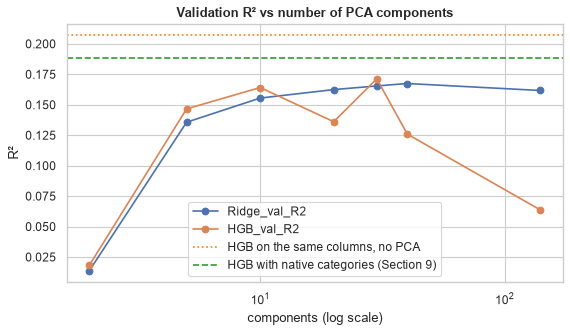

HGB on the same 140 columns without PCA: val R2 = 0.2069


,explained_var,Ridge_val_R2,HGB_val_R2
n_components,,,
2,0.3280,0.0138,0.0182
5,0.5778,0.1356,0.1466
10,0.7887,0.1555,0.1641
20,0.9063,0.1624,0.1361
30,0.9502,0.1654,0.1713
40,0.9686,0.1674,0.1259
140,1.0000,0.1617,0.0637


In [28]:
pca_rows = []
for k in [2, 5, 10, 20, 40, n_95, X_pca_train.shape[1]]:
    pca_k = PCA(n_components=k, random_state=RANDOM_STATE).fit(X_pca_train)
    Z_train, Z_val = pca_k.transform(X_pca_train), pca_k.transform(X_pca_val)
    ridge_r2 = r2_score(val_df[TARGET], Ridge().fit(Z_train, train_sub[TARGET]).predict(Z_val))
    hgb_r2 = r2_score(val_df[TARGET], HistGradientBoostingRegressor(**HGB_DEFAULTS).fit(Z_train, train_sub[TARGET]).predict(Z_val))
    pca_rows.append({"n_components": k, "explained_var": pca_k.explained_variance_ratio_.sum(),
                     "Ridge_val_R2": ridge_r2, "HGB_val_R2": hgb_r2})
pca_results = pd.DataFrame(pca_rows).set_index("n_components").sort_index()
hgb_on_dense = r2_score(val_df[TARGET], HistGradientBoostingRegressor(**HGB_DEFAULTS).fit(X_pca_train, train_sub[TARGET]).predict(X_pca_val))

fig, ax = plt.subplots(figsize=(8, 4.2))
pca_results[["Ridge_val_R2", "HGB_val_R2"]].plot(ax=ax, marker="o", logx=True)
ax.axhline(hgb_on_dense, color="tab:orange", ls=":", label="HGB on the same columns, no PCA")
ax.axhline(comparison.loc["HistGradientBoosting (default)", "R2"], color="tab:green", ls="--",
           label="HGB with native categories (Section 9)")
ax.set(title="Validation R² vs number of PCA components", xlabel="components (log scale)", ylabel="R²")
ax.legend()
plt.show()
print(f"HGB on the same {X_pca_train.shape[1]} columns without PCA: val R2 = {hgb_on_dense:.4f}")
pca_results

Observations:
* The one-hot space is very redundant: 20 components keep 90 % of the variance of the 140 columns, and 30 keep 95 %.
* PC1 and PC2 do not separate small and large fires: the large fires (dark points) are spread over the whole cloud. PC1/PC2 are driven by seasonality (DOY, MONTH, DOY_SIN) and location/reporting activity (longitude, frequency of the reporting unit). These directions have the most *feature* variance, which says nothing about the *target*. This is the main limitation of PCA, which is unsupervised.
* Ridge: 10 components already give 0.156 and 30–40 components give ≈ 0.166, slightly *better* than Ridge on all 140 columns (0.162). PCA acts as a mild regularisation and compresses the input 4× at no cost.
* Gradient boosting: PCA hurts. With all 140 components (a pure rotation, no information lost!), R² drops to 0.064, vs ≈ 0.21 on the same columns without PCA. Trees split along one feature at a time. A rotation mixes meaningful axes (longitude, one-hot flags) into oblique combinations, which the trees then need many splits to approximate.
* Side result: on the same one-hot columns, the default HGB gets ≈ 0.21, *more* than the default HGB with native categorical splits (0.188). Native categorical splits over 52 states or 38 source systems can overfit. One-hot encoding for the tuned model is worth trying.
* Conclusion: PCA is useful for visualisation and for compressing inputs to linear models, not for tree ensembles. We do not use it in the final model.

## 12. Ablation study
Why an ablation? Correlations (Section 6) look at one feature at a time, and importance scores are misleading when features are redundant: if we remove the latitude, the grid cell still tells the model where the fire is. Removing whole groups and retraining tells us what each kind of information really brings.

Which groups of features carry the signal? With the tuned HistGradientBoosting and the 300 k training subsample, we:
* remove one group at a time (drop in R² = what is *unique* to this group, i.e. not recoverable from the others);
* keep only one group (R² = what this group can explain *on its own*).

Then, for Scenario B, we measure what the duration adds, on the fires that have a valid duration.

In [29]:
def hgb_val_r2(features, train, val):
    model = make_hgb(features, **BEST_HGB_PARAMS).fit(train[features], train[TARGET])
    return r2_score(val[TARGET], model.predict(val[features]))


full_r2 = hgb_val_r2(FEATURES_A, train_sub, val_df)
ablation_rows = [{"experiment": "all features (A)", "val_R2": full_r2}]
for group, group_features in FEATURE_GROUPS.items():
    without = [f for f in FEATURES_A if f not in group_features]
    ablation_rows.append({"experiment": f"without {group}", "val_R2": hgb_val_r2(without, train_sub, val_df)})
    ablation_rows.append({"experiment": f"only {group}", "val_R2": hgb_val_r2(group_features, train_sub, val_df)})
ablation = pd.DataFrame(ablation_rows).set_index("experiment")
ablation["delta_vs_all"] = ablation["val_R2"] - full_r2
ablation

,val_R2,delta_vs_all
experiment,,
all features (A),0.2160,0.0000
without time,0.2022,-0.0138
only time,-0.0281,-0.2441
without space,0.1711,-0.0449
only space,0.1585,-0.0576
without cause,0.1969,-0.0191
only cause,0.0123,-0.2037
without reporting,0.1977,-0.0183
only reporting,0.1314,-0.0846


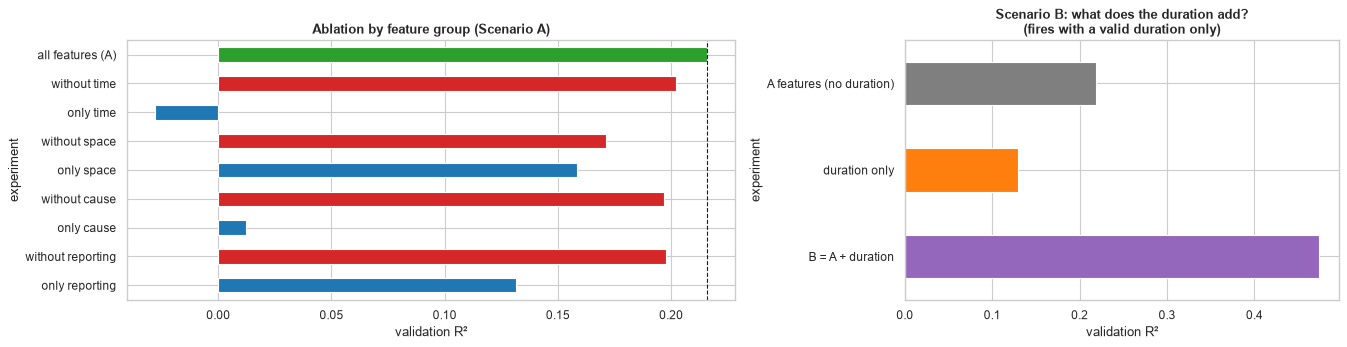

,val_R2
experiment,
A features (no duration),0.2182
duration only,0.1298
B = A + duration,0.4732


In [30]:
train_b = train_df.dropna(subset=["DURATION_DAYS"]).sample(300_000, random_state=RANDOM_STATE)
val_b = val_df.dropna(subset=["DURATION_DAYS"])
scenario_b = pd.DataFrame([
    {"experiment": "A features (no duration)", "val_R2": hgb_val_r2(FEATURES_A, train_b, val_b)},
    {"experiment": "duration only", "val_R2": hgb_val_r2(["DURATION_DAYS"], train_b, val_b)},
    {"experiment": "B = A + duration", "val_R2": hgb_val_r2(FEATURES_B, train_b, val_b)},
]).set_index("experiment")

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
colors = ["tab:green" if e.startswith("all") else "tab:red" if e.startswith("without") else "tab:blue" for e in ablation.index]
ablation["val_R2"].plot.barh(ax=axes[0], color=colors)
axes[0].axvline(full_r2, color="k", ls="--", lw=1)
axes[0].invert_yaxis()
axes[0].set(title="Ablation by feature group (Scenario A)", xlabel="validation R²")
scenario_b["val_R2"].plot.barh(ax=axes[1], color=["tab:gray", "tab:orange", "tab:purple"])
axes[1].invert_yaxis()
axes[1].set(title="Scenario B: what does the duration add?\n(fires with a valid duration only)", xlabel="validation R²")
plt.tight_layout()
plt.show()
scenario_b

Observations (Scenario A, validation R², all features = 0.216):

| group | removed (unique contribution) | alone |
|---|---|---|
| space (lat, lon, state, grid cell) | −0.045 | 0.159 |
| reporting (owner, agency, source, unit) | −0.018 | 0.131 |
| cause | −0.019 | 0.012 |
| time (year, season, hour, weekday) | −0.014 | −0.028 |

* Space is the most important group, both on its own and in what it uniquely adds.
* Reporting is strong on its own (0.131) but largely redundant with space (a reporting unit is a place), so removing it costs only 0.018.
* Cause alone predicts almost nothing (0.012), but removing it costs 0.019: its effect only appears in interaction with place and season (a lightning fire in Nevada in August is not the same as a lightning fire in Florida).
* Time alone is useless (negative R² on future years), but it adds 0.014 in combination (seasons and hours affect places differently).
* The unique contributions add up to 0.096, far below 0.216: the groups share a lot of information (location is encoded four times: coordinates, grid cell, state and reporting unit).

Scenario B: on fires with a valid duration, the A features give 0.218, duration alone gives 0.130, and A + duration gives 0.473, more than double. Duration interacts strongly with location: a 2-day fire in the Great Basin and a 2-day fire in Georgia are very different fires. This is why models that use the duration report much higher scores (Section 14). But duration is known only after the fire, so Scenario B *explains* fire sizes rather than *predicting* them.

## 13. Final evaluation on the test set (2014–2015)

The final model is the tuned HistGradientBoosting, Scenario A, retrained on all fires from 1992 to 2013 (train + validation). The test years have never been used for any decision. For reference, we evaluate the mean baseline and Ridge in exactly the same way.

Why retrain on train + validation? All decisions (model, hyperparameters, features) are now fixed, so the validation years are no longer needed for selection. They are the most recent years before the test period, and Section 7 showed that the data changes over time, so they are the most useful data to learn from. The test set is used once, here: if we went back and changed the model after looking at it, the test score would no longer be an honest estimate.

In [31]:
train_val_df = pd.concat([train_df, val_df])
final_models = {
    "Mean baseline": make_model(FEATURES_A, DummyRegressor(), "dense"),
    "Ridge": make_model(FEATURES_A, Ridge(alpha=ridge_scores["validation"].idxmax()), "dense"),
    "HistGradientBoosting (tuned)": make_hgb(FEATURES_A, **BEST_HGB_PARAMS),
}
test_results = {}
for name, model in final_models.items():
    model.fit(train_val_df[FEATURES_A], train_val_df[TARGET])
    test_results[name] = regression_report(test_df[TARGET], model.predict(test_df[FEATURES_A]))
final_model = final_models["HistGradientBoosting (tuned)"]
test_pred = final_model.predict(test_df[FEATURES_A])
test_results = pd.DataFrame(test_results).T
test_results["majority_class_acc"] = (test_df["SIZE_CLASS"] == train_val_df["SIZE_CLASS"].mode()[0]).mean()
test_results

,R2,RMSE,MAE,class_acc,majority_class_acc
Mean baseline,-0.0057,1.3454,0.9785,0.4489,0.4489
Ridge,-0.2076,1.4743,0.9616,0.4658,0.4489
HistGradientBoosting (tuned),0.1663,1.2250,0.8145,0.4881,0.4489


Observations:
* Final model, test R² = 0.166 (RMSE 1.225, MAE 0.815). On validation (model trained on 1992–2011) it was 0.227, so it loses ≈ 0.06 on 2014–2015. Section 13.2 explains why.
* Size-class accuracy is 48.8 %, only 4 points above always predicting the majority class B (44.9 %). This confirms that "accuracy on size classes" (as reported in some works of the SOTA) is a misleading metric for this dataset.
* Ridge collapses on the test set (R² = −0.21, worse than the mean), although it reached +0.16 on validation. A linear model *extrapolates* without limit: when the target-encoded history of a place no longer matches the new fires (see Kansas, Section 13.2), its prediction explodes for those fires (in our diagnostic, some tiny 2015 Kansas fires got predictions above 10, i.e. > 20,000 acres). Trees cannot predict outside the range of training values, which makes them much more robust to this kind of shift.

### 13.1 Where does the model fail?

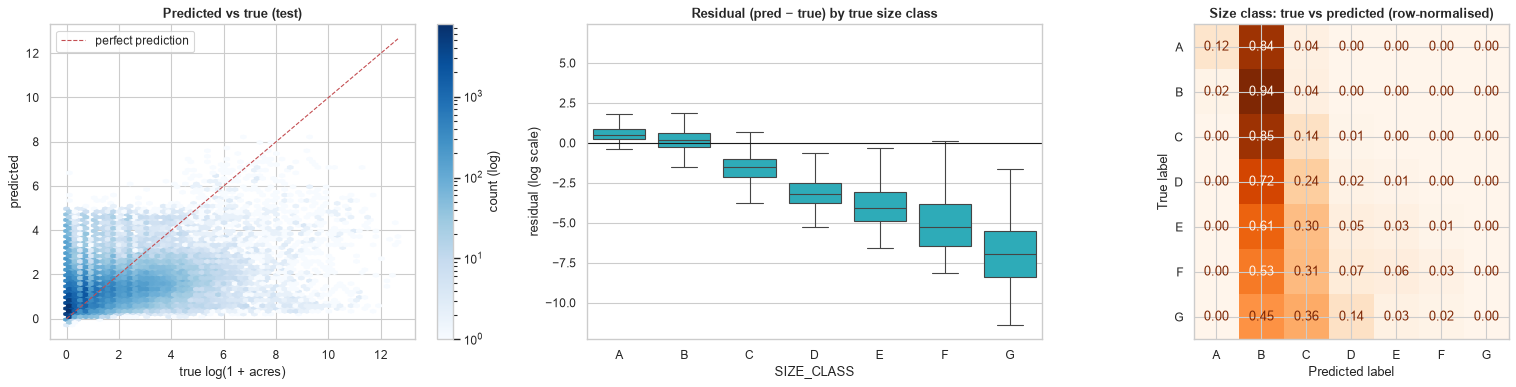

,n,MAE,mean_residual
SIZE_CLASS,,,
A,59600,0.6804,0.6782
B,63851,0.5703,0.2071
C,14935,1.5926,-1.4845
D,1963,3.0669,-3.0250
E,939,3.8603,-3.8303
F,550,4.9746,-4.9710
G,395,6.8968,-6.8968


In [32]:
test_eval = test_df[[TARGET, "SIZE_CLASS"]].assign(pred=test_pred, residual=test_pred - test_df[TARGET])
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
hb = axes[0].hexbin(test_eval[TARGET], test_eval["pred"], gridsize=60, bins="log", cmap="Blues")
lim = [0, test_eval[TARGET].max()]
axes[0].plot(lim, lim, "r--", lw=1, label="perfect prediction")
axes[0].set(xlabel="true log(1 + acres)", ylabel="predicted", title="Predicted vs true (test)")
axes[0].legend()
fig.colorbar(hb, ax=axes[0], label="count (log)")

sns.boxplot(data=test_eval, x="SIZE_CLASS", y="residual", order=list("ABCDEFG"), ax=axes[1], fliersize=0, color="tab:cyan")
axes[1].axhline(0, color="k", lw=1)
axes[1].set(title="Residual (pred − true) by true size class", ylabel="residual (log scale)")

ConfusionMatrixDisplay.from_predictions(test_eval["SIZE_CLASS"], to_size_class(np.expm1(np.clip(test_pred, 0, None))),
                                        labels=list("ABCDEFG"), normalize="true", values_format=".2f", ax=axes[2],
                                        cmap="Oranges", colorbar=False)
axes[2].set(title="Size class: true vs predicted (row-normalised)")
plt.tight_layout()
plt.show()
test_eval.groupby("SIZE_CLASS").agg(n=("residual", "size"), MAE=("residual", lambda r: r.abs().mean()),
                                    mean_residual=("residual", "mean"))

Observations:
* Regression to the mean. The predictions stay between 0 and ≈ 5 while the truth goes up to 13. Small fires (class A) are slightly overestimated (+0.68 in log), class B is well calibrated, and large fires are increasingly underestimated (class G: −6.9 in log, i.e. predicted ~1,000× too small).
* The confusion matrix shows the same thing: almost every fire is predicted as class B, 14 % of class C fires are recognised, and classes D–G are almost never predicted.
* This is the expected behaviour of a squared-loss regressor on a very noisy target. It predicts the conditional mean, and since a big fire looks like many small ones at discovery time, the conditional mean is never extreme. To *detect* large fires we need a dedicated, rebalanced classifier (Section 13.5) and not only a regression.

### 13.2 Why is the test score lower than the validation score? Temporal drift
The model trained on 1992–2011 is scored year by year on 2012–2015. While inspecting Ridge's large test errors, we found that most of its extreme predictions were Kansas fires in 2015, so we also look at Kansas separately.

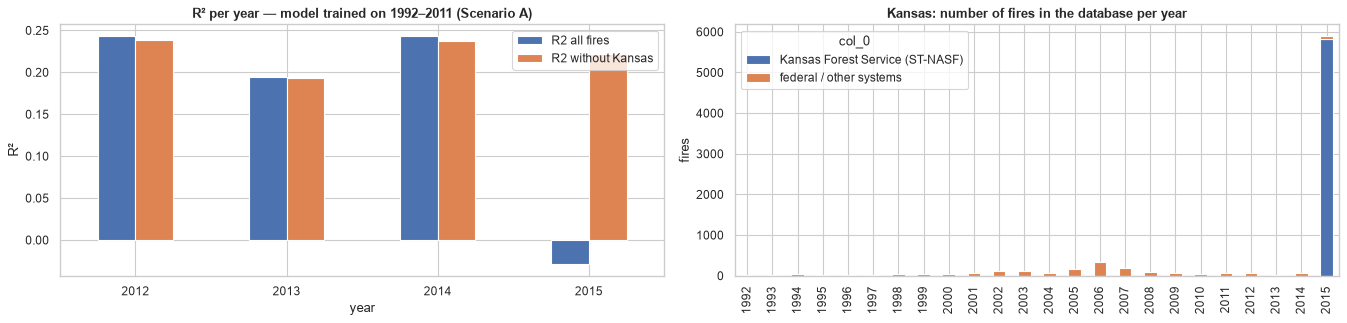

,n_fires,kansas_fires,R2 all fires,R2 without Kansas
year,,,,
2012,72746,73,0.2434,0.2382
2013,64753,14,0.1938,0.1932
2014,67752,59,0.2432,0.2369
2015,74481,5887,-0.0290,0.2215


,test R2 (all fires),test R2 without Kansas
Mean baseline,-0.0057,-0.0068
Ridge,-0.2076,0.1441
HistGradientBoosting (tuned),0.1663,0.2660


In [33]:
yearly_rows = []
for year in range(2012, 2016):
    part = df[df["FIRE_YEAR"] == year]
    without_kansas = part[part["STATE"] != "KS"]
    yearly_rows.append({
        "year": year, "n_fires": len(part), "kansas_fires": (part["STATE"] == "KS").sum(),
        "R2 all fires": r2_score(part[TARGET], hgb_full_train.predict(part[FEATURES_A])),
        "R2 without Kansas": r2_score(without_kansas[TARGET], hgb_full_train.predict(without_kansas[FEATURES_A])),
    })
yearly = pd.DataFrame(yearly_rows).set_index("year")

kansas = df[df["STATE"] == "KS"]
kansas_by_year = pd.crosstab(kansas["FIRE_YEAR"], np.where(kansas["SOURCE_SYSTEM"] == "ST-NASF",
                                                          "Kansas Forest Service (ST-NASF)", "federal / other systems"))
fig, axes = plt.subplots(1, 2, figsize=(17, 4.2))
yearly[["R2 all fires", "R2 without Kansas"]].plot.bar(ax=axes[0], rot=0)
axes[0].set(title="R² per year — model trained on 1992–2011 (Scenario A)", ylabel="R²")
kansas_by_year.plot.bar(stacked=True, ax=axes[1], rot=90)
axes[1].set(title="Kansas: number of fires in the database per year", ylabel="fires", xlabel="")
plt.tight_layout()
plt.show()

not_kansas = test_df["STATE"] != "KS"
display(yearly)
pd.DataFrame({
    name: {"test R2 (all fires)": test_results.loc[name, "R2"],
           "test R2 without Kansas": r2_score(test_df.loc[not_kansas, TARGET], model.predict(test_df.loc[not_kansas, FEATURES_A]))}
    for name, model in final_models.items()
}).T

Observations:
* The model trained on 1992–2011 gets R² = 0.243 in 2012, 0.194 in 2013 and 0.243 in 2014, but −0.029 in 2015, worse than predicting the mean. Without Kansas, 2015 goes back to 0.222, in line with the other years. The drop on the test set therefore comes almost entirely from one state in one year.
* Why Kansas? Before 2015 the database contained between 14 and 348 Kansas fires per year, almost all reported by federal agencies (median 5 acres, mean 447 acres). In 2015 it contains 5,887, of which 5,834 come from a new source, the Kansas Forest Service (`ST-NASF`), with a median of 1 acre and a mean of 16 acres. Kansas did not suddenly have 50 times more fires; the way they are recorded changed. What the model knows about Kansas (the target encoding of its grid cells and reporting units) was learned from the few, larger federal records, so it overestimates these thousands of small state records.
* On the whole test set (2014–2015), removing Kansas raises the R² of the final model from 0.166 to 0.266 and that of Ridge from −0.21 to +0.14. Ridge suffers much more because a linear model extrapolates its encoded features without limit, while trees stay within the range of sizes seen in training.
* We still report 0.166 as our test score. Removing Kansas after looking at the test results would mean choosing our test data, so 0.266 is a diagnostic, not a result.
* The practical lesson is that a model like this one must be monitored: a new reporting source can change the data without any change in the fires. Watching the number of records per source system and per state, and retraining when a new source appears, would have caught this.

### 13.3 Which features does the final model use? (permutation importance)
Permutation importance = how much the test R² drops when we randomly shuffle one feature (breaking its link with the target). It is computed on the raw features (before encoding), so it is easy to read. Unlike the impurity-based importance of trees, it is not biased towards high-cardinality features.

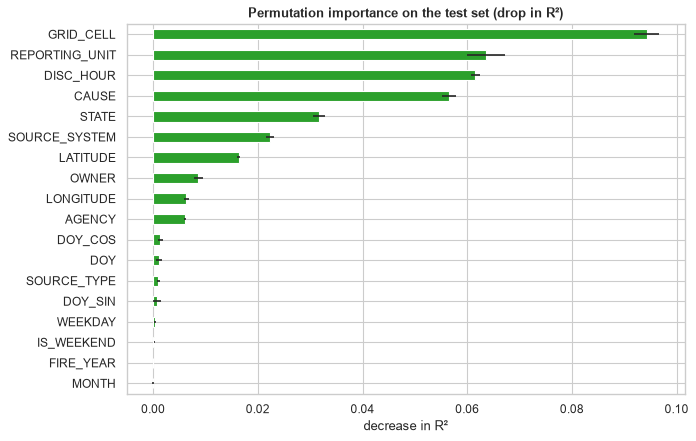

In [34]:
importance_sample = test_df.sample(40_000, random_state=RANDOM_STATE)
perm = permutation_importance(final_model, importance_sample[FEATURES_A], importance_sample[TARGET], scoring="r2",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
perm_importance = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std}, index=FEATURES_A)
perm_importance = perm_importance.sort_values("mean")

fig, ax = plt.subplots(figsize=(9, 6))
perm_importance["mean"].plot.barh(xerr=perm_importance["std"], ax=ax, color="tab:green")
ax.set(title="Permutation importance on the test set (drop in R²)", xlabel="decrease in R²")
plt.show()

Partial dependence plots. A good score is not enough: we also check that what the model learned makes physical sense. A partial dependence plot shows the average prediction when one feature varies and all the others are kept as they are. If the curves contradicted the EDA (Section 5), the model would be exploiting an artefact.

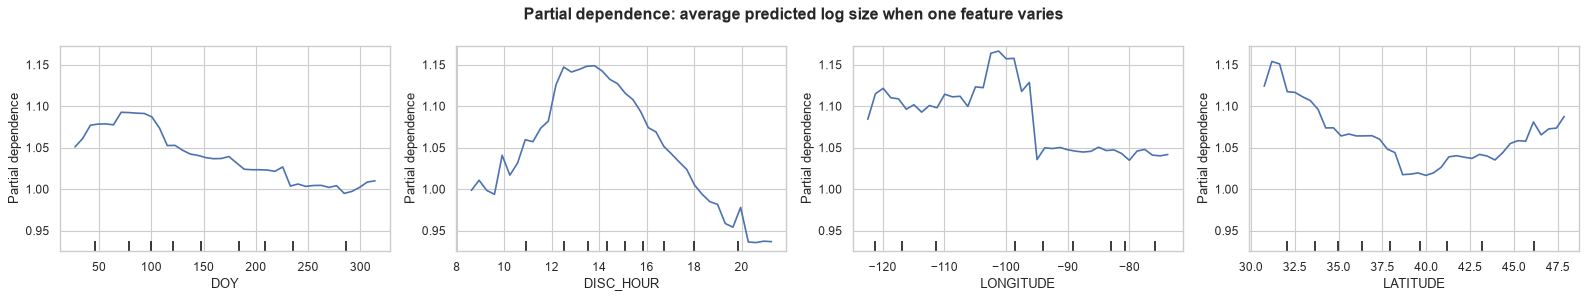

In [35]:
pdp_sample = importance_sample[FEATURES_A].dropna(subset=["DISC_HOUR"]).sample(5_000, random_state=RANDOM_STATE)
pdp_sample = pdp_sample.astype({c: float for c in pdp_sample.select_dtypes("integer").columns})  # PDP needs floats
fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
PartialDependenceDisplay.from_estimator(final_model, pdp_sample, ["DOY", "DISC_HOUR", "LONGITUDE", "LATITUDE"],
                                        grid_resolution=40, ax=ax)
plt.suptitle("Partial dependence: average predicted log size when one feature varies", fontweight="bold")
plt.tight_layout()
plt.show()

Observations:
* The grid cell is by far the most important feature (R² drops by 0.094 when it is shuffled): the past fire regime of a place is the best single predictor of the size of a new fire there. Then come the reporting unit (0.063), the discovery hour (0.061), the cause (0.056), the state (0.032) and the source system (0.022).
* The discovery hour ranks high for two reasons. Physically, afternoon fires grow more (see the partial dependence below). But whether the hour is recorded at all depends on the reporting system (Section 5.2), and shuffling the column also shuffles the missing values. Part of its importance is therefore reporting information.
* The season features (DOY, MONTH, DOY_SIN, DOY_COS) look useless, and latitude and longitude rank low. This does not mean the season or the location are unimportant: they are described by several redundant features, and when one is shuffled the model reads the same information from the others. This is the main weakness of permutation importance, and the reason why the ablation by group (Section 12) gives the more reliable picture. Both agree that location comes first.
* `FIRE_YEAR` has zero importance, which is reassuring: the model does not rely on a trend over years, which could not be extrapolated to future years.
* Partial dependence (average prediction while one feature varies):
  * Hour: the predicted size rises from about 1.00 at 9:00 to 1.15 at 13:00–14:00, then falls to 0.94 after 20:00. This is the afternoon peak of burning conditions (hottest, driest, windiest hours) seen in Section 5.3.
  * Day of year: highest between days 50 and 100 (February to April, the spring season before green-up), lowest in autumn.
  * Longitude: higher in the West with a maximum around −103° to −100° (the Great Plains), then a sharp drop near −98°. The model has learned the arid/humid divide of Section 5.5 as a threshold, which a linear model could not do.
  * Latitude: highest in the far South (30–33°), lowest around 40°, rising again in the North.
* All these effects are physically plausible and agree with the EDA, so the model is not exploiting an obvious artefact. Their amplitude is small (about ±0.1 in log size) because a partial dependence plot moves one feature at a time; most of the predictive power comes from interactions and from the encoded history of each place.

### 13.4 What R² means in practice
A test R² of 0.17 in log space sounds very low. What does it mean for an individual fire?

In [36]:
abs_log_error = (test_eval["pred"] - test_eval[TARGET]).abs()
baseline_error = (train_val_df[TARGET].mean() - test_eval[TARGET]).abs()
pd.DataFrame({
    "final model": [np.median(abs_log_error), np.mean(abs_log_error <= np.log(2)), np.mean(abs_log_error <= np.log(10))],
    "mean baseline": [np.median(baseline_error), np.mean(baseline_error <= np.log(2)), np.mean(baseline_error <= np.log(10))],
}, index=["median |log error|", "share within ~x2 of the true (1+acres)", "share within ~x10"])

,final model,mean baseline
median |log error|,0.5376,0.9025
share within ~x2 of the true (1+acres),0.6026,0.3561
share within ~x10,0.9344,0.9339


### 13.5 A practical use: flagging large fires at discovery
For firefighting, the question is often binary: *will this fire become large (≥ 100 acres)?* Only about 3 % of fires do, so accuracy is meaningless (always answering "no" gives 97 %). We use precision–recall curves and the average precision (AP), whose baseline is the positive rate.

We compare (i) a dedicated `HistGradientBoostingClassifier` with balanced class weights, trained on the same features, and (ii) simply using the regression prediction as a score.

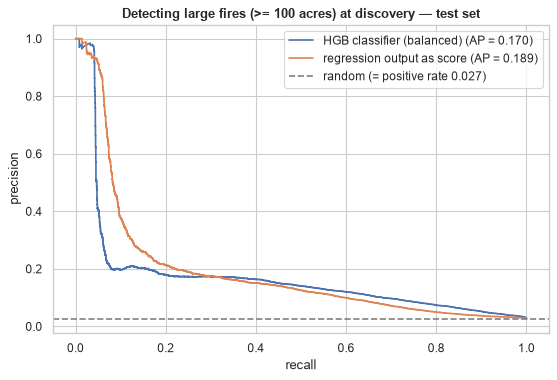

,ROC_AUC,AP,precision@top5%,recall@top5%
HGB classifier (balanced),0.8374,0.1702,0.1725,0.3189
regression output as score,0.7866,0.1892,0.1715,0.3171


In [37]:
large_classifier = make_hgb(FEATURES_A, classifier=True, class_weight="balanced",
                            **{k: v for k, v in BEST_HGB_PARAMS.items()})
large_classifier.fit(train_val_df[FEATURES_A], train_val_df["FIRE_SIZE"] >= 100)
y_large = (test_df["FIRE_SIZE"] >= 100).to_numpy()
scores = {"HGB classifier (balanced)": large_classifier.predict_proba(test_df[FEATURES_A])[:, 1],
          "regression output as score": test_pred}

fig, ax = plt.subplots(figsize=(8, 5))
large_rows = {}
for name, score in scores.items():
    precision, recall, _ = precision_recall_curve(y_large, score)
    ax.plot(recall, precision, label=f"{name} (AP = {average_precision_score(y_large, score):.3f})")
    top_5 = score >= np.quantile(score, 0.95)
    large_rows[name] = {"ROC_AUC": roc_auc_score(y_large, score), "AP": average_precision_score(y_large, score),
                        "precision@top5%": y_large[top_5].mean(), "recall@top5%": y_large[top_5].sum() / y_large.sum()}
ax.axhline(y_large.mean(), color="gray", ls="--", label=f"random (= positive rate {y_large.mean():.3f})")
ax.set(xlabel="recall", ylabel="precision", title="Detecting large fires (>= 100 acres) at discovery — test set")
ax.legend()
plt.show()
pd.DataFrame(large_rows).T

Observations:
* Only 2.7 % of test fires are large, so a random ranking has an average precision (AP) of 0.027.
* Both scores rank fires far better than random: ROC-AUC 0.837 for the dedicated classifier vs 0.787 for the regression output. AP is 0.170 vs 0.189, about 6–7× the random level.
* Operationally: if responders flag the 5 % of fires with the highest score, they catch ≈ 32 % of all large fires, with a precision of ≈ 17 % (vs 2.7 % at random, a 6.4× lift).
* The classifier ranks better overall (higher AUC), while the regression score is slightly better at the very top of the ranking (higher AP). Neither is good enough to replace human judgement, but both are useful for prioritising fires.

## 14. Why the evaluation protocol matters: naive setup vs honest setup
Our final R² (0.17 on test, 0.23 on validation) may look low. A straightforward setup, the one we would get without the checks of Sections 3–7, makes three choices that look harmless: (1) use the fire duration as a feature, (2) drop every row with a missing value, (3) use a random train/validation split. Such a setup reports a much higher score.

Why this section? To justify our protocol with numbers. We take a simple model (8 basic features, a large HGB with `max_leaf_nodes=511`, `l2_regularization=0.5`, `learning_rate=0.1`, `max_iter=1000`) and change the three choices one at a time, to see how much of the "naive" score each of them explains.

In [38]:
BASIC_FEATURES = ["FIRE_YEAR", "DOY", "DURATION_DAYS", "LATITUDE", "LONGITUDE", "STATE", "CAUSE", "OWNER"]
BASIC_HGB_PARAMS = dict(max_iter=1000, max_leaf_nodes=511, l2_regularization=0.5, learning_rate=0.1, min_samples_leaf=20)


def basic_setup_r2(data, features, split):
    if split == "random":
        train, temp = train_test_split(data, test_size=0.3, random_state=RANDOM_STATE)
        val, _ = train_test_split(temp, test_size=0.5, random_state=RANDOM_STATE)
    else:
        train, val = data[data["FIRE_YEAR"] <= 2011], data[data["FIRE_YEAR"].between(2012, 2013)]
    model = make_hgb(features, **BASIC_HGB_PARAMS).fit(train[features], train[TARGET])
    return r2_score(val[TARGET], model.predict(val[features]))


dropna_mask = ~df["COUNTY_MISSING"] & df["DURATION_DAYS"].notna()
setups = [
    ("1. naive: dropna (county + containment), random split, with duration", df[dropna_mask], BASIC_FEATURES, "random"),
    ("2. all fires with a valid duration, random split, with duration", df.dropna(subset=["DURATION_DAYS"]), BASIC_FEATURES, "random"),
    ("3. all fires with a valid duration, temporal split, with duration", df.dropna(subset=["DURATION_DAYS"]), BASIC_FEATURES, "temporal"),
    ("4. all fires, random split, without duration", df, [f for f in BASIC_FEATURES if f != "DURATION_DAYS"], "random"),
    ("5. all fires, temporal split, without duration", df, [f for f in BASIC_FEATURES if f != "DURATION_DAYS"], "temporal"),
]
protocol_comparison = pd.DataFrame([
    {"setup": name, "n_fires": len(data), "val_R2": basic_setup_r2(data, features, split)}
    for name, data, features, split in setups
]).set_index("setup")
protocol_comparison.loc["6. ours: all fires, temporal split, without duration, all A features + tuning (Section 10.3)"] = (
    len(df), learning_curve.loc[len(train_df), "R2"])
pd.set_option("display.max_colwidth", 120)
protocol_comparison

,n_fires,val_R2
setup,,
"1. naive: dropna (county + containment), random split, with duration",669500.0000,0.5444
"2. all fires with a valid duration, random split, with duration",988737.0000,0.5622
"3. all fires with a valid duration, temporal split, with duration",988737.0000,0.3918
"4. all fires, random split, without duration",1879691.0000,0.3087
"5. all fires, temporal split, without duration",1879691.0000,0.1387
"6. ours: all fires, temporal split, without duration, all A features + tuning (Section 10.3)",1879691.0000,0.2269


Observations: we change one factor at a time (validation R²):
* (1) The naive setup reaches 0.544, more than twice our honest score. This is the kind of number that is easy to report and hard to defend.
* (1) → (2): removing the `dropna` filter (keeping all fires that have a duration) gives 0.562. Dropping rows did not help.
* (2) → (3): random split → temporal split costs 0.17 of R² (0.562 → 0.392).
* (4) → (5): without duration, the same drop appears: 0.309 (random) → 0.139 (temporal). The random split is optimistic because fires from the same day and area (the same storm, the same complex) end up in both train and validation. The model then "recognises" its neighbours instead of generalising to new years.
* (3) → (5): removing the duration costs ≈ 0.25. Most of the naive score comes from duration (post-event information) and from the random split, not from the model.
* (5) → (6): under the same honest protocol, our features (reporting unit, source system, hour, grid-cell history, …) and the tuning raise R² from 0.139 to 0.227 (+63 %).

So our lower headline number is not a worse model. It answers a harder, more realistic question.

## 15. Conclusion

### What we did
1. Framed a realistic task: predict the final (log) burned area of a US wildfire at discovery time, from 1.88 M fires (1992–2015), with a separate "after containment" scenario (+ duration) as an upper bound.
2. Audited all 39 columns, proved that 5 of them leak the target (MTBS, ICS-209, complex and fire names, size class) and removed them.
3. Cleaned the data in one explicit function without dropping rows, after showing that missing values are not random. We engineered the discovery hour, cyclic seasonality, a 0.5° grid cell and the historical fire regime of each place (target and frequency encodings).
4. Explored and measured relevance with tools suited to a heavy-tailed target and categorical features (Spearman, η², mutual information).
5. Evaluated honestly: temporal split (train on the past, test on the future), every encoder fitted inside sklearn pipelines, the test set used once.
6. Compared 7 model families, studied bias/variance, tuned gradient boosting by random search, drew a learning curve, tested PCA, ran an ablation by feature group, and explained the model (permutation importance, partial dependence).

### Main results
| model (Scenario A) | validation R² (2012–13) | test R² (2014–15) |
|---|---|---|
| mean baseline | ≈ 0 | −0.006 |
| Ridge | 0.162 | −0.21 |
| HistGradientBoosting (tuned, all data) | 0.227 | 0.166 |

* Without the Kansas fires, whose recording changed in 2015 (Section 13.2), the final model reaches a test R² of 0.266. We report 0.166 as the honest score.
* With duration (Scenario B), R² rises to 0.47, but duration is only known after the fire.
* In practice, the final model is within a factor 2 of the true size for 60 % of fires (36 % for the baseline). Used as an alarm, the top 5 % of its scores catch ≈ 32 % of large fires (6.4× better than random).

### What we learned, and why
* The size of a fire is mostly decided after discovery. Wind, fuel moisture and how fast crews arrive are not in the data, so a large part of the variance is unpredictable at discovery. An R² of ≈ 0.2 is the honest level; scores above 0.5 need post-event information or an optimistic split (Section 14).
* Where a fire starts matters most. Location is the strongest group of features (ablation), mainly through the historical fire regime of the place (grid cell, reporting unit). Cause and season matter in interaction with location, which is why trees beat linear models.
* Gradient boosting is the right model family, as in the state of the art: it captures thresholds (the −100° longitude divide) and interactions, handles missing values, and cannot extrapolate beyond the training targets, which made it robust to the 2015 reporting change that broke Ridge.
* More data helps only up to a point. The learning curve flattens after ≈ 1 M fires: the limit is the information contained in the features, not the number of fires.
* PCA does not help here. It compresses the input for a linear model, but rotating the features destroys the axes that trees split on.
* The evaluation protocol matters as much as the model. A random split adds ≈ 0.17 of R². On the test set, a single change in how one state reports its fires (Kansas, 2015) lowers the R² from 0.27 to 0.17. A model of this kind must be monitored and retrained when reporting practices change.

### Limitations
* Large fires are underestimated by orders of magnitude (regression to the mean): a squared-error model predicts the conditional *mean*, and a future mega-fire looks like many small fires at discovery.
* Some features describe reporting practices rather than physics (reporting unit, source system). They improve the score but can change over time.
* Sizes are often rounded (0.1, 0.5, 1 acre), which limits the precision on small fires. The cause may be refined after the investigation, so it is not always known exactly at discovery.

### If we had more time
* Add weather at discovery (wind, humidity, temperature, drought indices, e.g. from gridMET or Open-Meteo). These are the main physical drivers missing from the data, and they *are* known at discovery time. This needs correctly decoded dates (Section 4).
* Add time-varying environmental covariates from FPA-FOD-Attributes (Pourmohamad et al., 2024): vegetation state, fuel, population. Fixed covariates such as soil type add little, because a tree model already identifies the place from its coordinates.
* Model the tail explicitly: quantile or extreme-value losses, or a two-stage model (large-fire classifier + size regressor), as in Koh (2023).
* Tune further: lower learning rate with more trees, one-hot inputs for gradient boosting (Section 11 hint), LightGBM/CatBoost.
* Use spatio-temporal cross-validation over several blocks of years for more stable model selection, and monitor reporting volumes per state to detect drift.